In [1]:
!pip install -q --upgrade clouddrift


In [2]:
import numpy as np
import pandas as pd
import clouddrift as cd

print("NumPy:", np.__version__)
print("CloudDrift imported successfully")

NumPy: 2.5.3
CloudDrift imported successfully


In [3]:
ds = cd.datasets.gdp1h()
print(ds)

<xarray.Dataset> Size: 16GB
Dimensions:                (traj: 19396, obs: 197214787)
Coordinates:
    id                     (traj) int64 155kB ...
    time                   (obs) datetime64[ns] 2GB ...
Dimensions without coordinates: traj, obs
Data variables: (12/58)
    BuoyTypeManufacturer   (traj) |S20 388kB ...
    BuoyTypeSensorArray    (traj) |S20 388kB ...
    CurrentProgram         (traj) float64 155kB ...
    DeployingCountry       (traj) |S20 388kB ...
    DeployingShip          (traj) |S20 388kB ...
    DeploymentComments     (traj) int16 39kB ...
    ...                     ...
    start_lat              (traj) float32 78kB ...
    start_lon              (traj) float32 78kB ...
    typebuoy               (traj) |S10 194kB ...
    typedeath              (traj) int8 19kB ...
    ve                     (obs) float32 789MB ...
    vn                     (obs) float32 789MB ...
Attributes: (12/18)
    Conventions:          CF-1.6
    acknowledgement:      Elipot, Shane; Sykuls

In [4]:
import numpy as np
import clouddrift as cd

# ============================================================
# 1. Load NOAA GDP hourly dataset
# ============================================================

ds = cd.datasets.gdp1h()

rowsize = ds["rowsize"].values.astype(np.int64)

traj_starts = np.concatenate(
    ([0], np.cumsum(rowsize)[:-1])
)

traj_ends = np.cumsum(rowsize)

n_obs = int(traj_ends[-1])
n_traj = len(rowsize)

print("GDP DATASET")
print("--------------------------------")
print(f"Number of trajectories: {n_traj:,}")
print(f"Number of observations: {n_obs:,}")


# ============================================================
# 2. Define North-central Gulf release region R
#
# Longitude: 94°W – 85°W
# Latitude:  26°N – 30.5°N
# ============================================================

R = {
    "lon_min": -94,
    "lon_max": -85,
    "lat_min": 26,
    "lat_max": 30.5
}

print("\nRELEASE REGION R")
print("--------------------------------")
print(
    f"Longitude: {R['lon_min']} to {R['lon_max']}"
)
print(
    f"Latitude:  {R['lat_min']} to {R['lat_max']}"
)


# ============================================================
# 3. Find first valid entry into R for each trajectory
#
# We scan in chunks because the full dataset contains
# ~197 million observations and should not be loaded into RAM
# at once.
# ============================================================

CHUNK = 2_000_000

# trajectory index -> first global observation index inside R
first_entry = {}

for start in range(0, n_obs, CHUNK):

    end = min(start + CHUNK, n_obs)

    lat = ds["lat"].isel(
        obs=slice(start, end)
    ).values

    lon = ds["lon"].isel(
        obs=slice(start, end)
    ).values

    # Valid observations inside North-central Gulf
    inside = (
        np.isfinite(lat)
        & np.isfinite(lon)
        & (lon >= R["lon_min"])
        & (lon <= R["lon_max"])
        & (lat >= R["lat_min"])
        & (lat <= R["lat_max"])
    )

    local_idx = np.flatnonzero(inside)

    if len(local_idx) == 0:
        continue

    # Convert chunk-relative index to global observation index
    global_idx = start + local_idx

    # Determine which trajectory each observation belongs to
    traj_idx = np.searchsorted(
        traj_ends,
        global_idx,
        side="right"
    )

    # Keep only the FIRST observation inside R
    # for each trajectory
    for ti, gi in zip(traj_idx, global_idx):

        if ti not in first_entry:
            first_entry[ti] = gi


n_enter = len(first_entry)

print("\nREGION SCREENING")
print("--------------------------------")
print(
    f"Trajectories entering North-central Gulf: "
    f"{n_enter:,}"
)


# ============================================================
# 4. Function to test future trajectory availability
#
# For each trajectory:
#
# first entry into R = t0
#
# Check whether there is a valid lat/lon observation around:
#
# t0 + 7 days
# t0 + 30 days
# t0 + 365 days
#
# Tolerance = ±3 hours
# ============================================================

TOLERANCE = np.timedelta64(3, "h")


def check_horizon(days):

    delta = np.timedelta64(days, "D")

    valid_trajectories = []

    for ti, entry_idx in first_entry.items():

        traj_end = traj_ends[ti]

        # Load this trajectory from first entry onwards
        times = ds["time"].isel(
            obs=slice(entry_idx, traj_end)
        ).values

        lat = ds["lat"].isel(
            obs=slice(entry_idx, traj_end)
        ).values

        lon = ds["lon"].isel(
            obs=slice(entry_idx, traj_end)
        ).values

        if len(times) == 0:
            continue

        t0 = times[0]

        if np.isnat(t0):
            continue

        target_time = t0 + delta

        # Valid time + position observations
        valid_obs = (
            ~np.isnat(times)
            & np.isfinite(lat)
            & np.isfinite(lon)
        )

        if not np.any(valid_obs):
            continue

        valid_indices = np.flatnonzero(valid_obs)

        # Find valid observation closest to target time
        differences = np.abs(
            times[valid_indices] - target_time
        )

        nearest_position = np.argmin(differences)

        nearest_idx = valid_indices[
            nearest_position
        ]

        nearest_difference = differences[
            nearest_position
        ]

        # Accept only if observation is within ±3 hours
        if nearest_difference <= TOLERANCE:

            valid_trajectories.append(
                {
                    "traj_index": int(ti),
                    "entry_idx": int(entry_idx),
                    "endpoint_idx": int(
                        entry_idx + nearest_idx
                    ),
                    "t0": t0,
                    "target_time": target_time,
                    "endpoint_time": times[
                        nearest_idx
                    ],
                    "start_lon": float(lon[0]),
                    "start_lat": float(lat[0]),
                    "end_lon": float(
                        lon[nearest_idx]
                    ),
                    "end_lat": float(
                        lat[nearest_idx]
                    )
                }
            )

    return valid_trajectories


# ============================================================
# 5. Check 7-day, 30-day and 365-day availability
# ============================================================

print("\nChecking 7-day trajectories...")
valid_7d = check_horizon(7)

print("Checking 30-day trajectories...")
valid_30d = check_horizon(30)

print("Checking 365-day trajectories...")
valid_365d = check_horizon(365)


# ============================================================
# 6. Results
# ============================================================

print("\n")
print("=" * 55)
print("NORTH-CENTRAL GULF DATA ADEQUACY")
print("=" * 55)

print(
    f"Release-region trajectories: "
    f"{n_enter:,}"
)

print("--------------------------------")

print(
    f"Valid 7-day trajectories:   "
    f"{len(valid_7d):,}"
)

print(
    f"Valid 30-day trajectories:  "
    f"{len(valid_30d):,}"
)

print(
    f"Valid 365-day trajectories: "
    f"{len(valid_365d):,}"
)

print("--------------------------------")

if n_enter > 0:

    print(
        f"7-day availability:   "
        f"{len(valid_7d) / n_enter:.1%}"
    )

    print(
        f"30-day availability:  "
        f"{len(valid_30d) / n_enter:.1%}"
    )

    print(
        f"365-day availability: "
        f"{len(valid_365d) / n_enter:.1%}"
    )

print("=" * 55)

GDP DATASET
--------------------------------
Number of trajectories: 19,396
Number of observations: 197,214,787

RELEASE REGION R
--------------------------------
Longitude: -94 to -85
Latitude:  26 to 30.5

REGION SCREENING
--------------------------------
Trajectories entering North-central Gulf: 197

Checking 7-day trajectories...
Checking 30-day trajectories...
Checking 365-day trajectories...


NORTH-CENTRAL GULF DATA ADEQUACY
Release-region trajectories: 197
--------------------------------
Valid 7-day trajectories:   191
Valid 30-day trajectories:  150
Valid 365-day trajectories: 32
--------------------------------
7-day availability:   97.0%
30-day availability:  76.1%
365-day availability: 16.2%


In [7]:
!pip -q install cartopy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 59.7 MB/s eta 0:00:00


In [8]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np


# ============================================================
# Function: load complete trajectory segment from t0 to endpoint
# ============================================================

def get_segments(valid_list):

    segments = []

    for item in valid_list:

        start_idx = item["entry_idx"]
        end_idx = item["endpoint_idx"] + 1

        lat = ds["lat"].isel(
            obs=slice(start_idx, end_idx)
        ).values

        lon = ds["lon"].isel(
            obs=slice(start_idx, end_idx)
        ).values

        time = ds["time"].isel(
            obs=slice(start_idx, end_idx)
        ).values

        valid = (
            np.isfinite(lat)
            & np.isfinite(lon)
            & ~np.isnat(time)
        )

        lat = lat[valid]
        lon = lon[valid]
        time = time[valid]

        if len(lat) < 2:
            continue

        segments.append({
            "traj_index": item["traj_index"],
            "lat": lat,
            "lon": lon,
            "time": time,
            "start_lon": lon[0],
            "start_lat": lat[0],
            "end_lon": lon[-1],
            "end_lat": lat[-1]
        })

    return segments


# ============================================================
# Build trajectory segments
# ============================================================

print("Loading 7-day trajectory segments...")
segments_7d = get_segments(valid_7d)

print("Loading 30-day trajectory segments...")
segments_30d = get_segments(valid_30d)

print("Loading 365-day trajectory segments...")
segments_365d = get_segments(valid_365d)

print("\nSegments ready:")
print("7-day:  ", len(segments_7d))
print("30-day: ", len(segments_30d))
print("365-day:", len(segments_365d))

Loading 7-day trajectory segments...
Loading 30-day trajectory segments...
Loading 365-day trajectory segments...

Segments ready:
7-day:   191
30-day:  150
365-day: 32


In [10]:
# ============================================================
# 3. Plot trajectory map
#    Each historical trajectory has a different colour
# ============================================================

def plot_trajectory_map(segments, days):

    if len(segments) == 0:
        print(f"No valid {days}-day trajectories.")
        return

    # --------------------------------------------------------
    # Determine map extent from actual trajectories
    # --------------------------------------------------------

    all_lon = np.concatenate([
        s["lon"] for s in segments
    ])

    all_lat = np.concatenate([
        s["lat"] for s in segments
    ])

    lon_min = np.nanmin(all_lon)
    lon_max = np.nanmax(all_lon)

    lat_min = np.nanmin(all_lat)
    lat_max = np.nanmax(all_lat)

    lon_pad = max(
        3,
        (lon_max - lon_min) * 0.08
    )

    lat_pad = max(
        2,
        (lat_max - lat_min) * 0.08
    )

    extent = [
        max(-180, lon_min - lon_pad),
        min(180, lon_max + lon_pad),
        max(-90, lat_min - lat_pad),
        min(90, lat_max + lat_pad)
    ]


    # --------------------------------------------------------
    # Create map
    # --------------------------------------------------------

    fig = plt.figure(figsize=(13, 8))

    ax = plt.axes(
        projection=ccrs.PlateCarree()
    )

    ax.set_extent(
        extent,
        crs=ccrs.PlateCarree()
    )


    # --------------------------------------------------------
    # Base map
    # --------------------------------------------------------

    ax.add_feature(
        cfeature.OCEAN,
        facecolor="white",
        zorder=0
    )

    ax.add_feature(
        cfeature.LAND,
        facecolor="0.90",
        zorder=1
    )

    ax.add_feature(
        cfeature.COASTLINE,
        linewidth=0.7,
        zorder=5
    )

    ax.add_feature(
        cfeature.BORDERS,
        linewidth=0.4,
        zorder=5
    )


    # --------------------------------------------------------
    # Plot trajectories
    # Different trajectory = different colour
    # --------------------------------------------------------

    cmap = plt.colormaps["turbo"]

    n = len(segments)

    for k, seg in enumerate(segments):

        colour = cmap(
            k / max(n - 1, 1)
        )

        ax.plot(
            seg["lon"],
            seg["lat"],
            color=colour,
            linewidth=1.0,
            alpha=0.75,
            transform=ccrs.PlateCarree(),
            zorder=2
        )


    # --------------------------------------------------------
    # Starting points = first entry into R
    # --------------------------------------------------------

    ax.scatter(
        [s["start_lon"] for s in segments],
        [s["start_lat"] for s in segments],
        s=12,
        marker="o",
        color="black",
        alpha=0.75,
        transform=ccrs.PlateCarree(),
        zorder=6,
        label="First entry ($t_0$)"
    )


    # --------------------------------------------------------
    # Endpoints
    # --------------------------------------------------------

    ax.scatter(
        [s["end_lon"] for s in segments],
        [s["end_lat"] for s in segments],
        s=22,
        marker="x",
        color="black",
        linewidth=0.8,
        transform=ccrs.PlateCarree(),
        zorder=7,
        label=f"{days}-day endpoint"
    )


    # --------------------------------------------------------
    # North-central Gulf release-region boundary
    # R = 94W–85W, 26N–30.5N
    # --------------------------------------------------------

    x0 = R["lon_min"]
    x1 = R["lon_max"]

    y0 = R["lat_min"]
    y1 = R["lat_max"]

    ax.plot(
        [x0, x1, x1, x0, x0],
        [y0, y0, y1, y1, y0],
        color="black",
        linestyle="--",
        linewidth=2,
        transform=ccrs.PlateCarree(),
        zorder=8,
        label="Release region R"
    )


    # --------------------------------------------------------
    # Gridlines
    # --------------------------------------------------------

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.4,
        alpha=0.4,
        linestyle="--"
    )

    gl.top_labels = False
    gl.right_labels = False


    # --------------------------------------------------------
    # Title
    # --------------------------------------------------------

    ax.set_title(
        f"North-central Gulf: Valid {days}-day Historical Trajectories",
        fontsize=15,
        fontweight="bold",
        pad=16
    )

    ax.text(
        0.5,
        1.01,
        (
            f"First entry into R as $t_0$ | "
            f"Tolerance ±3 h | "
            f"n = {len(segments)}"
        ),
        transform=ax.transAxes,
        ha="center",
        fontsize=10
    )


    ax.legend(
        loc="lower left",
        fontsize=9
    )

    plt.tight_layout()
    plt.show()

/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_ocean.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


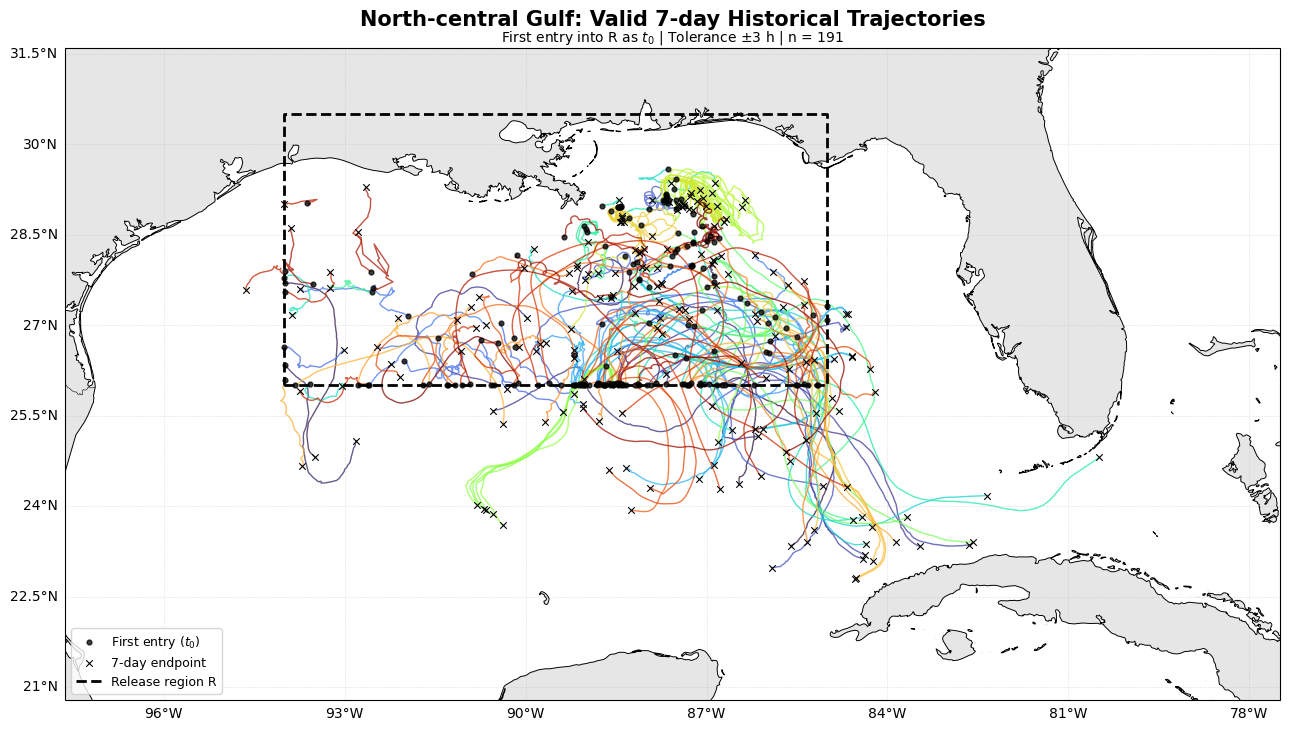

/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_ocean.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


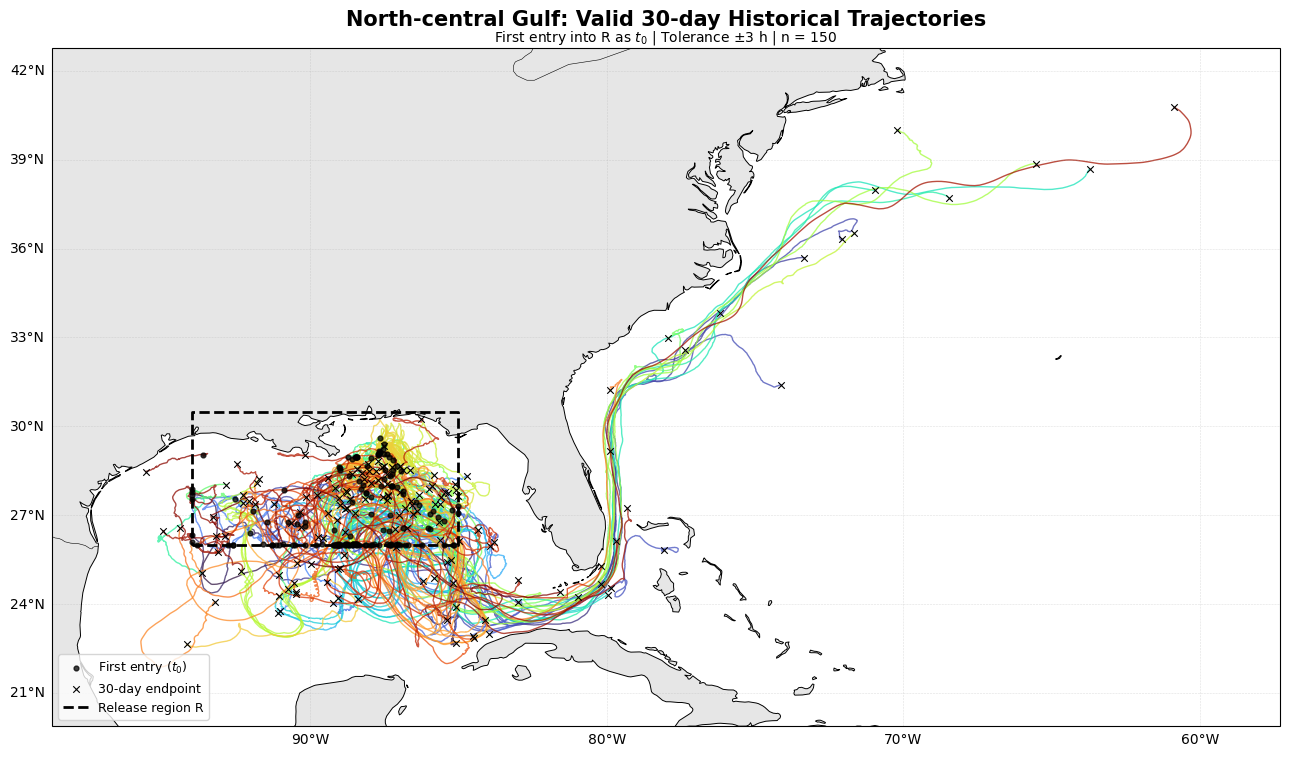

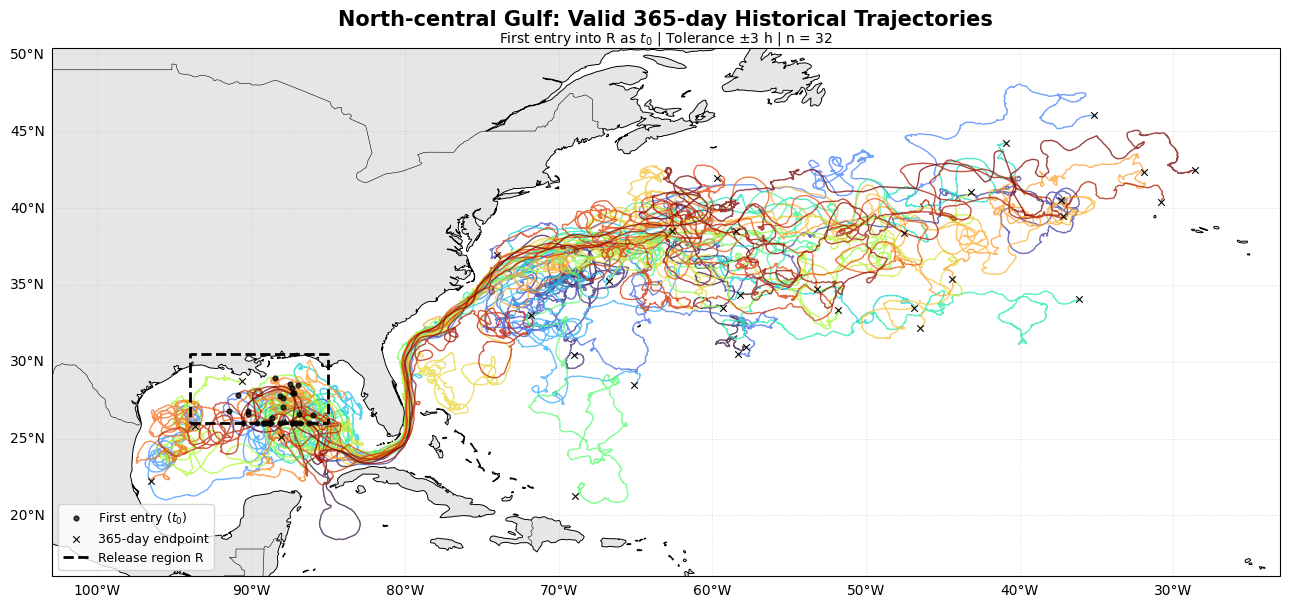

In [11]:
# ============================================================
# 4. Generate the three figures
# ============================================================

plot_trajectory_map(
    segments_7d,
    7
)

plot_trajectory_map(
    segments_30d,
    30
)

plot_trajectory_map(
    segments_365d,
    365
)

In [12]:
# ============================================================
# GULF STREAM RELEASE REGION
# ============================================================

import numpy as np

R_GS = {
    "lon_min": -75,
    "lon_max": -50,
    "lat_min": 30,
    "lat_max": 45
}

print("GULF STREAM RELEASE REGION")
print("--------------------------------")
print(f"Longitude: {R_GS['lon_min']} to {R_GS['lon_max']}")
print(f"Latitude:  {R_GS['lat_min']} to {R_GS['lat_max']}")


# ============================================================
# 1. Find first valid entry into Gulf Stream R
# ============================================================

CHUNK = 2_000_000
n_obs = int(traj_ends[-1])

first_entry_GS = {}

for start in range(0, n_obs, CHUNK):

    end = min(start + CHUNK, n_obs)

    lat = ds["lat"].isel(obs=slice(start, end)).values
    lon = ds["lon"].isel(obs=slice(start, end)).values

    inside = (
        np.isfinite(lat)
        & np.isfinite(lon)
        & (lon >= R_GS["lon_min"])
        & (lon <= R_GS["lon_max"])
        & (lat >= R_GS["lat_min"])
        & (lat <= R_GS["lat_max"])
    )

    local_idx = np.flatnonzero(inside)

    if len(local_idx) == 0:
        continue

    global_idx = start + local_idx

    traj_idx = np.searchsorted(
        traj_ends,
        global_idx,
        side="right"
    )

    # First observation inside R for each drifter
    for ti, gi in zip(traj_idx, global_idx):
        if ti not in first_entry_GS:
            first_entry_GS[ti] = gi


n_enter_GS = len(first_entry_GS)

print("\nREGION SCREENING")
print("--------------------------------")
print(
    f"Trajectories entering Gulf Stream: "
    f"{n_enter_GS:,}"
)


# ============================================================
# 2. Check future observation availability
# ============================================================

TOLERANCE = np.timedelta64(3, "h")


def check_horizon_GS(days):

    delta = np.timedelta64(days, "D")

    valid_trajectories = []

    for ti, entry_idx in first_entry_GS.items():

        traj_end = traj_ends[ti]

        # Load trajectory from first entry onwards
        times = ds["time"].isel(
            obs=slice(entry_idx, traj_end)
        ).values

        lat = ds["lat"].isel(
            obs=slice(entry_idx, traj_end)
        ).values

        lon = ds["lon"].isel(
            obs=slice(entry_idx, traj_end)
        ).values

        if len(times) == 0:
            continue

        t0 = times[0]

        if np.isnat(t0):
            continue

        target_time = t0 + delta

        valid_obs = (
            ~np.isnat(times)
            & np.isfinite(lat)
            & np.isfinite(lon)
        )

        if not np.any(valid_obs):
            continue

        valid_indices = np.flatnonzero(valid_obs)

        differences = np.abs(
            times[valid_indices] - target_time
        )

        nearest_position = np.argmin(differences)

        nearest_idx = valid_indices[nearest_position]

        nearest_difference = differences[nearest_position]

        # Endpoint must be within ±3 hours
        if nearest_difference <= TOLERANCE:

            valid_trajectories.append({
                "traj_index": int(ti),

                "entry_idx": int(entry_idx),

                "endpoint_idx": int(
                    entry_idx + nearest_idx
                ),

                "t0": t0,

                "target_time": target_time,

                "endpoint_time": times[nearest_idx],

                "start_lon": float(lon[0]),
                "start_lat": float(lat[0]),

                "end_lon": float(lon[nearest_idx]),
                "end_lat": float(lat[nearest_idx])
            })

    return valid_trajectories


# ============================================================
# 3. 7 / 30 / 365 days
# ============================================================

print("\nChecking 7-day trajectories...")
valid_GS_7d = check_horizon_GS(7)

print("Checking 30-day trajectories...")
valid_GS_30d = check_horizon_GS(30)

print("Checking 365-day trajectories...")
valid_GS_365d = check_horizon_GS(365)


# ============================================================
# 4. Data-adequacy results
# ============================================================

print("\n")
print("=" * 55)
print("GULF STREAM DATA ADEQUACY")
print("=" * 55)

print(
    f"Release-region trajectories: "
    f"{n_enter_GS:,}"
)

print("--------------------------------")

print(
    f"Valid 7-day trajectories:   "
    f"{len(valid_GS_7d):,}"
)

print(
    f"Valid 30-day trajectories:  "
    f"{len(valid_GS_30d):,}"
)

print(
    f"Valid 365-day trajectories: "
    f"{len(valid_GS_365d):,}"
)

print("--------------------------------")

if n_enter_GS > 0:

    print(
        f"7-day availability:   "
        f"{len(valid_GS_7d) / n_enter_GS:.1%}"
    )

    print(
        f"30-day availability:  "
        f"{len(valid_GS_30d) / n_enter_GS:.1%}"
    )

    print(
        f"365-day availability: "
        f"{len(valid_GS_365d) / n_enter_GS:.1%}"
    )

print("=" * 55)

GULF STREAM RELEASE REGION
--------------------------------
Longitude: -75 to -50
Latitude:  30 to 45

REGION SCREENING
--------------------------------
Trajectories entering Gulf Stream: 1,216

Checking 7-day trajectories...
Checking 30-day trajectories...
Checking 365-day trajectories...


GULF STREAM DATA ADEQUACY
Release-region trajectories: 1,216
--------------------------------
Valid 7-day trajectories:   1,188
Valid 30-day trajectories:  1,143
Valid 365-day trajectories: 540
--------------------------------
7-day availability:   97.7%
30-day availability:  94.0%
365-day availability: 44.4%


In [13]:
# ============================================================
# Extract trajectory segments from t0 to endpoint
# ============================================================

def get_segments_GS(valid_list):

    segments = []

    for item in valid_list:

        start_idx = item["entry_idx"]
        end_idx = item["endpoint_idx"] + 1

        lat = ds["lat"].isel(
            obs=slice(start_idx, end_idx)
        ).values

        lon = ds["lon"].isel(
            obs=slice(start_idx, end_idx)
        ).values

        time = ds["time"].isel(
            obs=slice(start_idx, end_idx)
        ).values

        valid = (
            np.isfinite(lat)
            & np.isfinite(lon)
            & ~np.isnat(time)
        )

        lat = lat[valid]
        lon = lon[valid]
        time = time[valid]

        if len(lat) < 2:
            continue

        segments.append({
            "traj_index": item["traj_index"],

            "lat": lat,
            "lon": lon,
            "time": time,

            "start_lon": lon[0],
            "start_lat": lat[0],

            "end_lon": lon[-1],
            "end_lat": lat[-1]
        })

    return segments


print("Loading Gulf Stream 7-day segments...")
segments_GS_7d = get_segments_GS(valid_GS_7d)

print("Loading Gulf Stream 30-day segments...")
segments_GS_30d = get_segments_GS(valid_GS_30d)

print("Loading Gulf Stream 365-day segments...")
segments_GS_365d = get_segments_GS(valid_GS_365d)


print("\nSegments ready")
print("--------------------------------")
print(f"7-day:   {len(segments_GS_7d):,}")
print(f"30-day:  {len(segments_GS_30d):,}")
print(f"365-day: {len(segments_GS_365d):,}")

Loading Gulf Stream 7-day segments...
Loading Gulf Stream 30-day segments...
Loading Gulf Stream 365-day segments...

Segments ready
--------------------------------
7-day:   1,188
30-day:  1,143
365-day: 540


In [14]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature


def plot_GS_trajectory_map(segments, days):

    if len(segments) == 0:
        print(f"No valid {days}-day trajectories.")
        return

    # ========================================================
    # Actual trajectory extent
    # ========================================================

    all_lon = np.concatenate([
        s["lon"] for s in segments
    ])

    all_lat = np.concatenate([
        s["lat"] for s in segments
    ])

    lon_min = np.nanmin(all_lon)
    lon_max = np.nanmax(all_lon)

    lat_min = np.nanmin(all_lat)
    lat_max = np.nanmax(all_lat)

    lon_pad = max(
        3,
        (lon_max - lon_min) * 0.08
    )

    lat_pad = max(
        2,
        (lat_max - lat_min) * 0.08
    )

    extent = [
        max(-180, lon_min - lon_pad),
        min(180, lon_max + lon_pad),
        max(-90, lat_min - lat_pad),
        min(90, lat_max + lat_pad)
    ]


    # ========================================================
    # Map
    # ========================================================

    fig = plt.figure(figsize=(13, 8))

    ax = plt.axes(
        projection=ccrs.PlateCarree()
    )

    ax.set_extent(
        extent,
        crs=ccrs.PlateCarree()
    )

    ax.add_feature(
        cfeature.OCEAN,
        facecolor="white",
        zorder=0
    )

    ax.add_feature(
        cfeature.LAND,
        facecolor="0.90",
        zorder=1
    )

    ax.add_feature(
        cfeature.COASTLINE,
        linewidth=0.7,
        zorder=5
    )

    ax.add_feature(
        cfeature.BORDERS,
        linewidth=0.4,
        zorder=5
    )


    # ========================================================
    # Trajectories
    # Different trajectory = different colour
    # ========================================================

    cmap = plt.colormaps["turbo"]

    n = len(segments)

    for k, seg in enumerate(segments):

        colour = cmap(
            k / max(n - 1, 1)
        )

        ax.plot(
            seg["lon"],
            seg["lat"],
            color=colour,
            linewidth=0.9,
            alpha=0.70,
            transform=ccrs.PlateCarree(),
            zorder=2
        )


    # ========================================================
    # Starting events t0
    # ========================================================

    ax.scatter(
        [s["start_lon"] for s in segments],
        [s["start_lat"] for s in segments],
        s=10,
        marker="o",
        color="black",
        alpha=0.65,
        transform=ccrs.PlateCarree(),
        zorder=6,
        label="First entry ($t_0$)"
    )


    # ========================================================
    # Endpoints
    # ========================================================

    ax.scatter(
        [s["end_lon"] for s in segments],
        [s["end_lat"] for s in segments],
        s=20,
        marker="x",
        color="black",
        linewidth=0.7,
        transform=ccrs.PlateCarree(),
        zorder=7,
        label=f"{days}-day endpoint"
    )


    # ========================================================
    # Gulf Stream release region
    # ========================================================

    x0 = R_GS["lon_min"]
    x1 = R_GS["lon_max"]

    y0 = R_GS["lat_min"]
    y1 = R_GS["lat_max"]

    ax.plot(
        [x0, x1, x1, x0, x0],
        [y0, y0, y1, y1, y0],
        color="black",
        linestyle="--",
        linewidth=2,
        transform=ccrs.PlateCarree(),
        zorder=8,
        label="Release region R"
    )


    # ========================================================
    # Grid
    # ========================================================

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.4,
        alpha=0.4,
        linestyle="--"
    )

    gl.top_labels = False
    gl.right_labels = False


    # ========================================================
    # Title
    # ========================================================

    ax.set_title(
        f"Gulf Stream: Valid {days}-day Historical Trajectories",
        fontsize=15,
        fontweight="bold",
        pad=16
    )

    ax.text(
        0.5,
        1.01,
        (
            f"First entry into R as $t_0$ | "
            f"Tolerance ±3 h | "
            f"n = {len(segments):,}"
        ),
        transform=ax.transAxes,
        ha="center",
        fontsize=10
    )

    ax.legend(
        loc="lower left",
        fontsize=9
    )

    plt.tight_layout()
    plt.show()

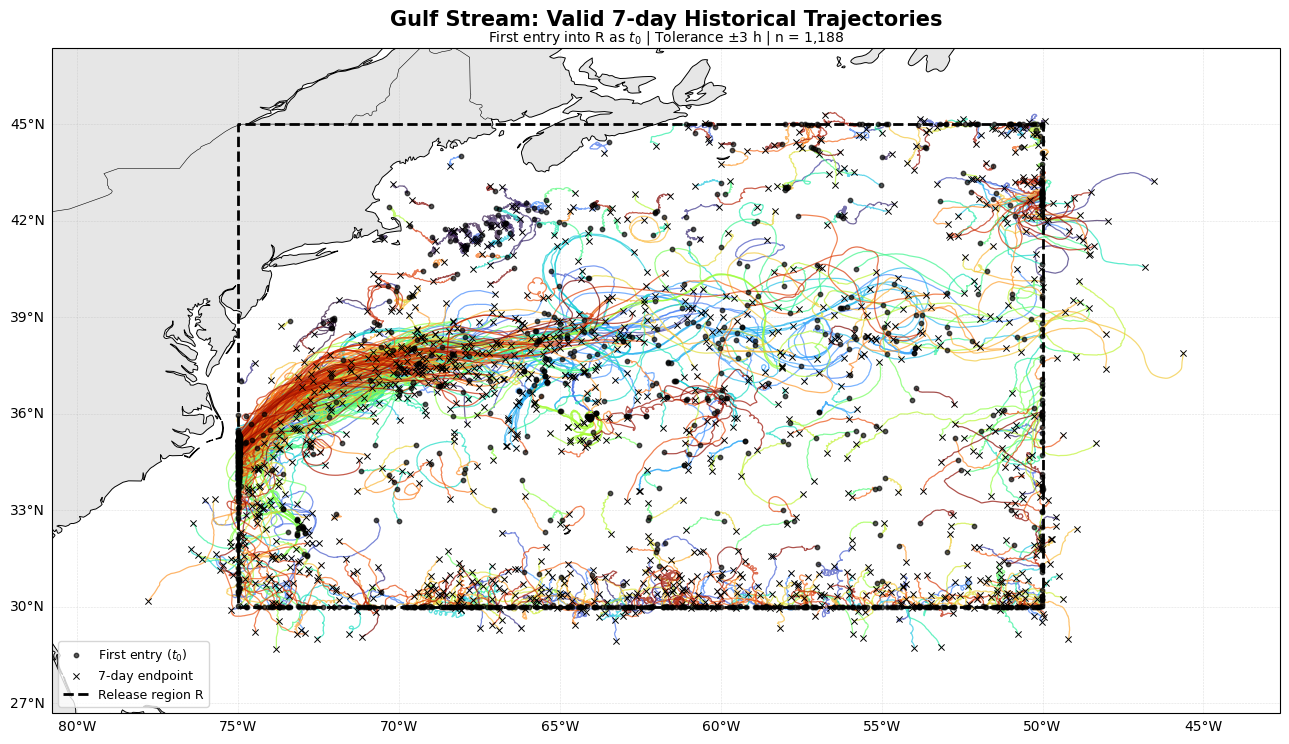

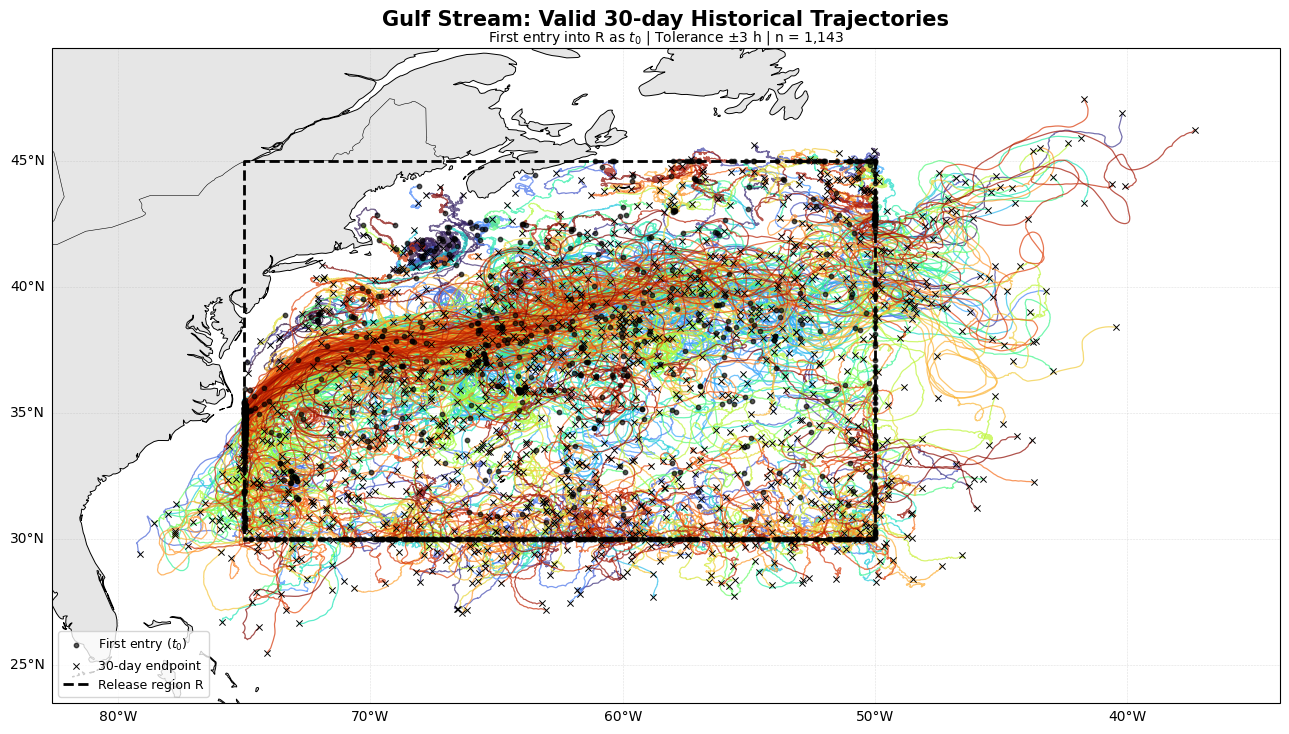

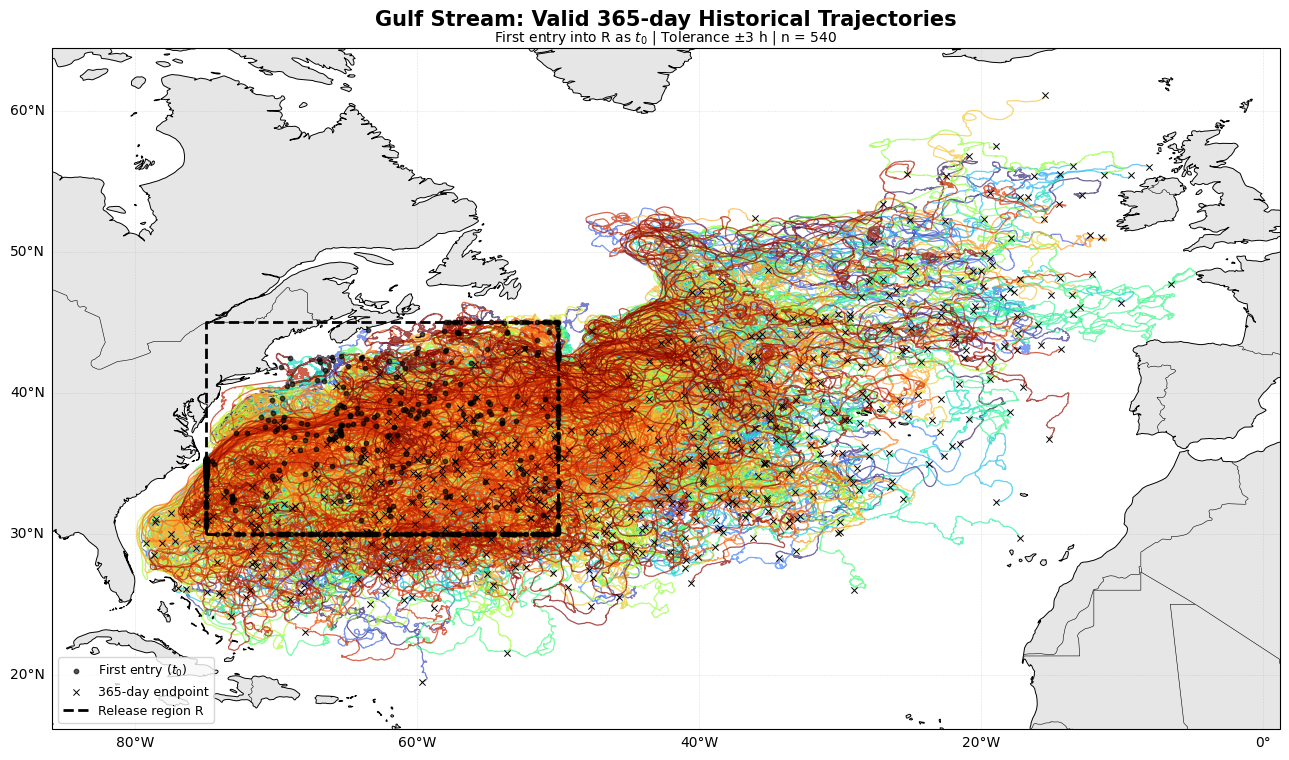

In [15]:
plot_GS_trajectory_map(
    segments_GS_7d,
    7
)

plot_GS_trajectory_map(
    segments_GS_30d,
    30
)

plot_GS_trajectory_map(
    segments_GS_365d,
    365
)

In [4]:
# ============================================================
# Build trajectory start/end indices
# ============================================================

rowsize = ds["rowsize"].values.astype(np.int64)

traj_starts = np.concatenate(
    ([0], np.cumsum(rowsize)[:-1])
)

traj_ends = np.cumsum(rowsize)

n_obs = int(traj_ends[-1])
n_traj = len(rowsize)

print(f"Total trajectories: {n_traj:,}")
print(f"Total observations: {n_obs:,}")

Total trajectories: 19,396
Total observations: 197,214,787


In [6]:
import time
# ============================================================
# Find trajectories entering Florida-Bahamas
# Region R: 85°W–75°W, 20°N–30°N
# ============================================================

west, east = -85, -75
south, north = 20, 30

florida_bahamas_trajs = set()

CHUNK = 2_000_000

print("Scanning GDP observations for Florida-Bahamas...")
t_start = time.time()

for start in range(0, n_obs, CHUNK):

    end = min(start + CHUNK, n_obs)

    lat = ds["lat"].isel(obs=slice(start, end)).values
    lon = ds["lon"].isel(obs=slice(start, end)).values

    valid = np.isfinite(lat) & np.isfinite(lon)

    inside = (
        valid &
        (lon >= west) &
        (lon < east) &
        (lat >= south) &
        (lat < north)
    )

    if np.any(inside):

        obs_idx = np.arange(
            start, end, dtype=np.int64
        )[inside]

        traj_idx = np.searchsorted(
            traj_ends,
            obs_idx,
            side="right"
        )

        florida_bahamas_trajs.update(
            np.unique(traj_idx).tolist()
        )

    if start % 20_000_000 == 0:
        print(
            f"Processed {start:,} / {n_obs:,}"
        )

print("\nFinished.")
print(
    f"Florida-Bahamas trajectories: "
    f"{len(florida_bahamas_trajs):,}"
)
print(
    f"Time: {(time.time()-t_start)/60:.1f} minutes"
)

Scanning GDP observations for Florida-Bahamas...
Processed 0 / 197,214,787
Processed 20,000,000 / 197,214,787
Processed 40,000,000 / 197,214,787
Processed 60,000,000 / 197,214,787
Processed 80,000,000 / 197,214,787
Processed 100,000,000 / 197,214,787
Processed 120,000,000 / 197,214,787
Processed 140,000,000 / 197,214,787
Processed 160,000,000 / 197,214,787
Processed 180,000,000 / 197,214,787

Finished.
Florida-Bahamas trajectories: 608
Time: 0.5 minutes


In [7]:
# ============================================================
# Florida-Bahamas trajectory continuity
# Check 7-day, 30-day and 365-day destination availability
# ============================================================

TOLERANCE_HOURS = 3
tolerance = np.timedelta64(TOLERANCE_HOURS, "h")

candidate_ids = sorted(florida_bahamas_trajs)

valid_7d = 0
valid_30d = 0
valid_365d = 0
valid_all = 0
actual_entries = 0

t_start = time.time()

print(f"Checking {len(candidate_ids):,} Florida-Bahamas trajectories...")
print(f"Tolerance: ±{TOLERANCE_HOURS} hours\n")

for j, traj_idx in enumerate(candidate_ids):

    start = traj_starts[traj_idx]
    end = traj_ends[traj_idx]

    # Read each trajectory once
    lat = ds["lat"].isel(obs=slice(start, end)).values
    lon = ds["lon"].isel(obs=slice(start, end)).values
    time_arr = ds["time"].isel(obs=slice(start, end)).values

    # Valid observations
    valid = (
        np.isfinite(lat) &
        np.isfinite(lon) &
        ~np.isnat(time_arr)
    )

    # Inside Florida-Bahamas
    inside = (
        valid &
        (lon >= west) &
        (lon < east) &
        (lat >= south) &
        (lat < north)
    )

    if not np.any(inside):
        continue

    actual_entries += 1

    # t0 = first valid observation inside Region R
    first_inside_idx = np.flatnonzero(inside)[0]
    t0 = time_arr[first_inside_idx]

    # Lead times
    target_7d = t0 + np.timedelta64(7, "D")
    target_30d = t0 + np.timedelta64(30, "D")
    target_365d = t0 + np.timedelta64(365, "D")

    # Valid observations after t0
    later_times = time_arr[
        valid & (time_arr >= t0)
    ]

    # Observation available within ±3 hours?
    has_7d = np.any(
        np.abs(later_times - target_7d) <= tolerance
    )

    has_30d = np.any(
        np.abs(later_times - target_30d) <= tolerance
    )

    has_365d = np.any(
        np.abs(later_times - target_365d) <= tolerance
    )

    valid_7d += int(has_7d)
    valid_30d += int(has_30d)
    valid_365d += int(has_365d)

    valid_all += int(
        has_7d and has_30d and has_365d
    )

    if (j + 1) % 100 == 0:
        print(f"{j+1:,} / {len(candidate_ids):,}")


# ============================================================
# Results
# ============================================================

continuity_results = pd.DataFrame([{
    "Region": "Florida-Bahamas",
    "Entering_trajectories": actual_entries,

    "Valid_7d": valid_7d,
    "Valid_7d_pct": 100 * valid_7d / actual_entries,

    "Valid_30d": valid_30d,
    "Valid_30d_pct": 100 * valid_30d / actual_entries,

    "Valid_365d": valid_365d,
    "Valid_365d_pct": 100 * valid_365d / actual_entries,

    "Valid_all": valid_all,
    "Valid_all_pct": 100 * valid_all / actual_entries
}])

print("\n" + "=" * 90)
print("FLORIDA-BAHAMAS TRAJECTORY CONTINUITY")
print("=" * 90)

display(
    continuity_results.style.format({
        "Valid_7d_pct": "{:.1f}%",
        "Valid_30d_pct": "{:.1f}%",
        "Valid_365d_pct": "{:.1f}%",
        "Valid_all_pct": "{:.1f}%"
    })
)

print(
    f"\nFinished in "
    f"{(time.time()-t_start)/60:.1f} minutes."
)

Checking 608 Florida-Bahamas trajectories...
Tolerance: ±3 hours

100 / 608
200 / 608
300 / 608
400 / 608
500 / 608
600 / 608

FLORIDA-BAHAMAS TRAJECTORY CONTINUITY


,Region,Entering_trajectories,Valid_7d,Valid_7d_pct,Valid_30d,Valid_30d_pct,Valid_365d,Valid_365d_pct,Valid_all,Valid_all_pct
0,Florida-Bahamas,608,568,93.4%,477,78.5%,174,28.6%,173,28.5%



Finished in 2.2 minutes.


In [8]:
# ============================================================
# SPATIAL SUPPORT CHECK
# Florida-Bahamas
#
# 2° x 2° starting cells
# Starting location = first valid observation inside Region R
#
# For each cell, count:
# - entering trajectories
# - trajectories valid at +7 days
# - trajectories valid at +30 days
# - trajectories valid at +365 days
# ============================================================

import numpy as np
import pandas as pd
import time

# Region R
west, east = -85, -75
south, north = 20, 30

# Grid resolution
GRID_SIZE = 2.0

lon_edges = np.arange(west, east + GRID_SIZE, GRID_SIZE)
lat_edges = np.arange(south, north + GRID_SIZE, GRID_SIZE)

TOLERANCE_HOURS = 3
tolerance = np.timedelta64(TOLERANCE_HOURS, "h")

records = []

t_start = time.time()

print("Checking spatial support for Florida-Bahamas...")
print(f"Grid size: {GRID_SIZE}° x {GRID_SIZE}°")
print(f"Trajectories: {len(florida_bahamas_trajs):,}\n")


for j, traj_idx in enumerate(sorted(florida_bahamas_trajs)):

    start = traj_starts[traj_idx]
    end = traj_ends[traj_idx]

    # Read trajectory once
    lat = ds["lat"].isel(obs=slice(start, end)).values
    lon = ds["lon"].isel(obs=slice(start, end)).values
    time_arr = ds["time"].isel(obs=slice(start, end)).values

    # Valid observations
    valid = (
        np.isfinite(lat) &
        np.isfinite(lon) &
        ~np.isnat(time_arr)
    )

    # Inside Florida-Bahamas
    inside = (
        valid &
        (lon >= west) &
        (lon < east) &
        (lat >= south) &
        (lat < north)
    )

    if not np.any(inside):
        continue

    # --------------------------------------------------------
    # t0 = first valid observation inside Region R
    # --------------------------------------------------------
    first_inside_idx = np.flatnonzero(inside)[0]

    start_lon = float(lon[first_inside_idx])
    start_lat = float(lat[first_inside_idx])
    t0 = time_arr[first_inside_idx]

    # Which 2° x 2° cell contains the starting location?
    lon_bin = int(np.floor((start_lon - west) / GRID_SIZE))
    lat_bin = int(np.floor((start_lat - south) / GRID_SIZE))

    cell_west = west + lon_bin * GRID_SIZE
    cell_east = cell_west + GRID_SIZE

    cell_south = south + lat_bin * GRID_SIZE
    cell_north = cell_south + GRID_SIZE

    # Forecast horizons
    target_7d = t0 + np.timedelta64(7, "D")
    target_30d = t0 + np.timedelta64(30, "D")
    target_365d = t0 + np.timedelta64(365, "D")

    later_times = time_arr[
        valid & (time_arr >= t0)
    ]

    has_7d = np.any(
        np.abs(later_times - target_7d) <= tolerance
    )

    has_30d = np.any(
        np.abs(later_times - target_30d) <= tolerance
    )

    has_365d = np.any(
        np.abs(later_times - target_365d) <= tolerance
    )

    records.append({
        "traj_idx": traj_idx,
        "start_lon": start_lon,
        "start_lat": start_lat,
        "t0": t0,

        "cell_west": cell_west,
        "cell_east": cell_east,
        "cell_south": cell_south,
        "cell_north": cell_north,

        "valid_7d": int(has_7d),
        "valid_30d": int(has_30d),
        "valid_365d": int(has_365d)
    })

    if (j + 1) % 100 == 0:
        print(
            f"Processed {j+1:,} / "
            f"{len(florida_bahamas_trajs):,}"
        )


# ============================================================
# Trajectory-level dataframe
# ============================================================

spatial_support_raw = pd.DataFrame(records)

print("\nTrajectory-level records:",
      len(spatial_support_raw))


# ============================================================
# Aggregate by starting cell
# ============================================================

cell_support = (
    spatial_support_raw
    .groupby(
        [
            "cell_west",
            "cell_east",
            "cell_south",
            "cell_north"
        ],
        as_index=False
    )
    .agg(
        Entering_trajectories=("traj_idx", "nunique"),
        Valid_7d=("valid_7d", "sum"),
        Valid_30d=("valid_30d", "sum"),
        Valid_365d=("valid_365d", "sum")
    )
)

# Percentages within each starting cell
cell_support["Valid_7d_pct"] = (
    100 *
    cell_support["Valid_7d"] /
    cell_support["Entering_trajectories"]
)

cell_support["Valid_30d_pct"] = (
    100 *
    cell_support["Valid_30d"] /
    cell_support["Entering_trajectories"]
)

cell_support["Valid_365d_pct"] = (
    100 *
    cell_support["Valid_365d"] /
    cell_support["Entering_trajectories"]
)

# Friendly cell label
cell_support["Cell"] = (
    cell_support["cell_west"].astype(int).astype(str)
    + " to "
    + cell_support["cell_east"].astype(int).astype(str)
    + "° lon, "
    + cell_support["cell_south"].astype(int).astype(str)
    + " to "
    + cell_support["cell_north"].astype(int).astype(str)
    + "° lat"
)

# Put useful columns first
cell_support = cell_support[
    [
        "Cell",
        "cell_west",
        "cell_east",
        "cell_south",
        "cell_north",
        "Entering_trajectories",
        "Valid_7d",
        "Valid_7d_pct",
        "Valid_30d",
        "Valid_30d_pct",
        "Valid_365d",
        "Valid_365d_pct"
    ]
]

# Sort by latitude north-to-south, longitude west-to-east
cell_support = cell_support.sort_values(
    ["cell_south", "cell_west"],
    ascending=[False, True]
).reset_index(drop=True)


print(
    f"\nFinished in "
    f"{(time.time()-t_start)/60:.1f} minutes."
)

display(
    cell_support.style.format({
        "Valid_7d_pct": "{:.1f}%",
        "Valid_30d_pct": "{:.1f}%",
        "Valid_365d_pct": "{:.1f}%"
    })
)

Checking spatial support for Florida-Bahamas...
Grid size: 2.0° x 2.0°
Trajectories: 608

Processed 100 / 608
Processed 200 / 608
Processed 300 / 608
Processed 400 / 608
Processed 500 / 608
Processed 600 / 608

Trajectory-level records: 608

Finished in 2.2 minutes.


,Cell,cell_west,cell_east,cell_south,cell_north,Entering_trajectories,Valid_7d,Valid_7d_pct,Valid_30d,Valid_30d_pct,Valid_365d,Valid_365d_pct
0,"-85 to -83° lon, 28 to 30° lat",-85.000000,-83.000000,28.000000,30.000000,7,7,100.0%,6,85.7%,1,14.3%
1,"-81 to -79° lon, 28 to 30° lat",-81.000000,-79.000000,28.000000,30.000000,14,14,100.0%,13,92.9%,4,28.6%
2,"-79 to -77° lon, 28 to 30° lat",-79.000000,-77.000000,28.000000,30.000000,23,22,95.7%,22,95.7%,5,21.7%
3,"-77 to -75° lon, 28 to 30° lat",-77.000000,-75.000000,28.000000,30.000000,51,50,98.0%,46,90.2%,16,31.4%
4,"-85 to -83° lon, 26 to 28° lat",-85.000000,-83.000000,26.000000,28.000000,45,45,100.0%,31,68.9%,13,28.9%
5,"-83 to -81° lon, 26 to 28° lat",-83.000000,-81.000000,26.000000,28.000000,2,2,100.0%,2,100.0%,0,0.0%
6,"-81 to -79° lon, 26 to 28° lat",-81.000000,-79.000000,26.000000,28.000000,118,116,98.3%,107,90.7%,45,38.1%
7,"-79 to -77° lon, 26 to 28° lat",-79.000000,-77.000000,26.000000,28.000000,3,3,100.0%,3,100.0%,2,66.7%
8,"-77 to -75° lon, 26 to 28° lat",-77.000000,-75.000000,26.000000,28.000000,82,82,100.0%,74,90.2%,28,34.1%
9,"-85 to -83° lon, 24 to 26° lat",-85.000000,-83.000000,24.000000,26.000000,74,69,93.2%,50,67.6%,18,24.3%


In [9]:
print("SANITY CHECK")
print("-" * 50)

print(
    "Entering trajectories:",
    cell_support["Entering_trajectories"].sum()
)

print(
    "Valid 7d:",
    cell_support["Valid_7d"].sum()
)

print(
    "Valid 30d:",
    cell_support["Valid_30d"].sum()
)

print(
    "Valid 365d:",
    cell_support["Valid_365d"].sum()
)

SANITY CHECK
--------------------------------------------------
Entering trajectories: 608
Valid 7d: 568
Valid 30d: 477
Valid 365d: 174


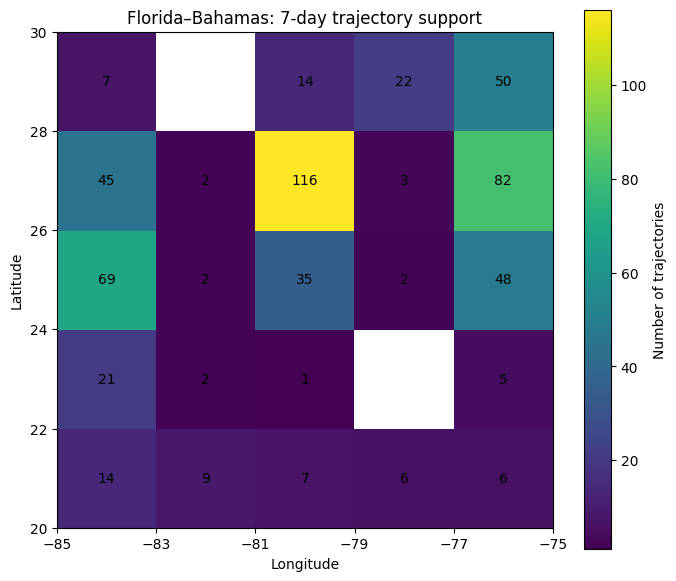

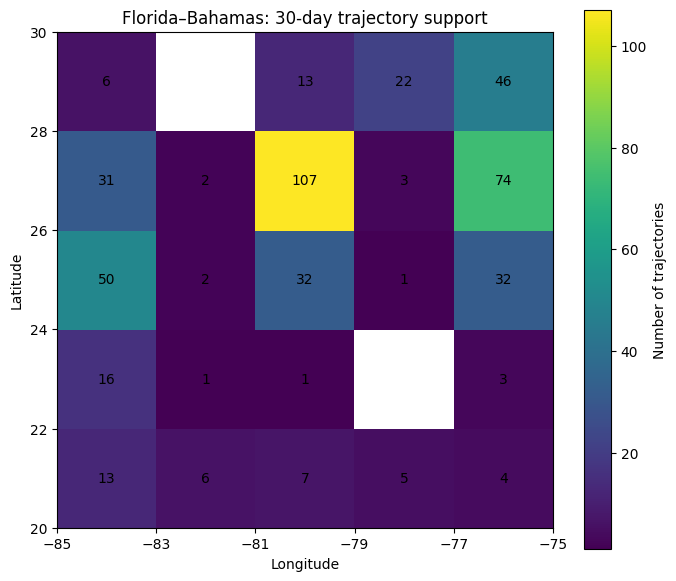

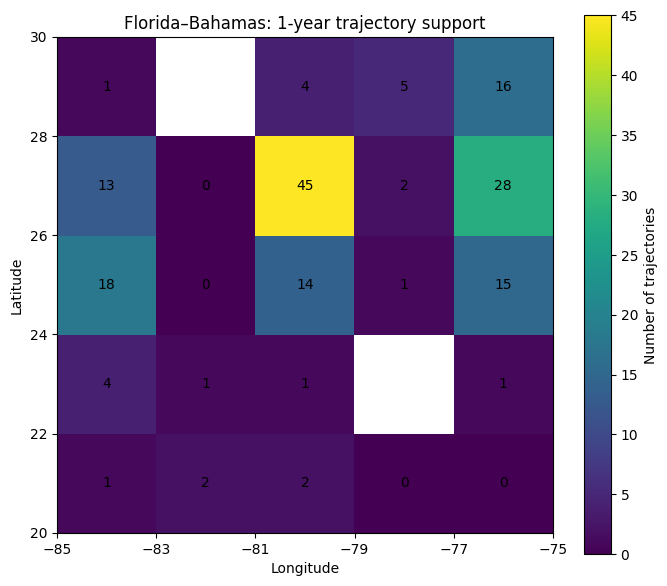

In [10]:
import matplotlib.pyplot as plt

def plot_support_map(df, value_col, title):

    grid = np.zeros((5, 5))
    grid[:] = np.nan

    for _, row in df.iterrows():

        lon_idx = int(
            (row["cell_west"] - west) / GRID_SIZE
        )

        lat_idx = int(
            (row["cell_south"] - south) / GRID_SIZE
        )

        grid[lat_idx, lon_idx] = row[value_col]

    fig, ax = plt.subplots(figsize=(8, 7))

    im = ax.imshow(
        grid,
        origin="lower",
        extent=[west, east, south, north],
        aspect="equal"
    )

    plt.colorbar(
        im,
        ax=ax,
        label="Number of trajectories"
    )

    # Write counts inside cells
    for _, row in df.iterrows():

        x = (
            row["cell_west"] +
            row["cell_east"]
        ) / 2

        y = (
            row["cell_south"] +
            row["cell_north"]
        ) / 2

        ax.text(
            x,
            y,
            f'{int(row[value_col])}',
            ha="center",
            va="center",
            fontsize=10
        )

    ax.set_xlim(west, east)
    ax.set_ylim(south, north)

    ax.set_xticks(np.arange(west, east + 1, 2))
    ax.set_yticks(np.arange(south, north + 1, 2))

    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

    ax.set_title(title)

    plt.show()


plot_support_map(
    cell_support,
    "Valid_7d",
    "Florida–Bahamas: 7-day trajectory support"
)

plot_support_map(
    cell_support,
    "Valid_30d",
    "Florida–Bahamas: 30-day trajectory support"
)

plot_support_map(
    cell_support,
    "Valid_365d",
    "Florida–Bahamas: 1-year trajectory support"
)

In [3]:
import numpy as np
import matplotlib.pyplot as plt

regions = {
    "Gulf Stream": (-75, -50, 30, 45),
    "Kuroshio": (125, 155, 20, 42)
}

density = {}

# 建立 1° × 1° 网格
for name, (west, east, south, north) in regions.items():
    lon_edges = np.arange(west, east + 1, 1)
    lat_edges = np.arange(south, north + 1, 1)

    density[name] = {
        "grid": np.zeros(
            (len(lat_edges) - 1, len(lon_edges) - 1),
            dtype=np.int64
        ),
        "lon_edges": lon_edges,
        "lat_edges": lat_edges
    }

# 分块读取真实 GDP 数据
chunk_size = 1_000_000
n_obs = ds.sizes["obs"]

for start in range(0, n_obs, chunk_size):

    end = min(start + chunk_size, n_obs)

    lon = ds["lon"].isel(obs=slice(start, end)).values
    lat = ds["lat"].isel(obs=slice(start, end)).values

    for name, (west, east, south, north) in regions.items():

        mask = (
            (lon >= west) & (lon < east) &
            (lat >= south) & (lat < north)
        )

        if np.any(mask):
            H, _, _ = np.histogram2d(
                lat[mask],
                lon[mask],
                bins=[
                    density[name]["lat_edges"],
                    density[name]["lon_edges"]
                ]
            )

            density[name]["grid"] += H.astype(np.int64)

    if start % 20_000_000 == 0:
        print(f"Processed {start:,} / {n_obs:,}")

print("Finished!")

Processed 0 / 197,214,787
Processed 20,000,000 / 197,214,787
Processed 40,000,000 / 197,214,787
Processed 60,000,000 / 197,214,787
Processed 80,000,000 / 197,214,787
Processed 100,000,000 / 197,214,787
Processed 120,000,000 / 197,214,787
Processed 140,000,000 / 197,214,787
Processed 160,000,000 / 197,214,787
Processed 180,000,000 / 197,214,787
Finished!


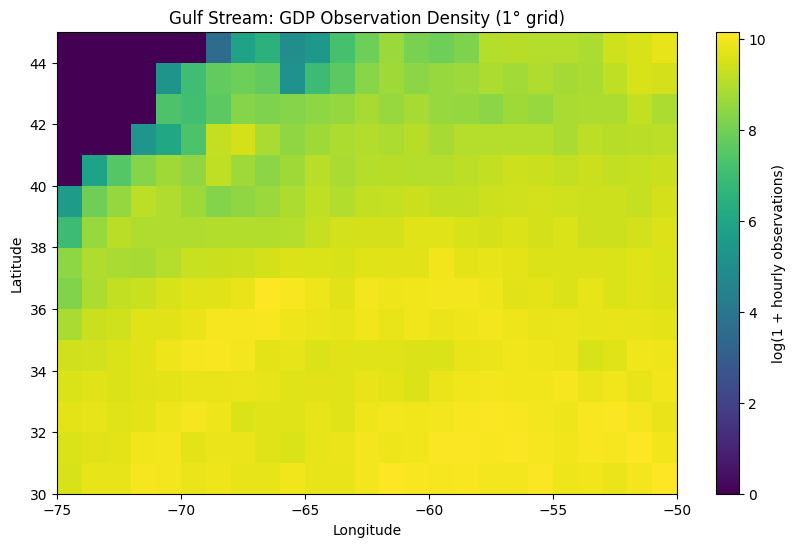

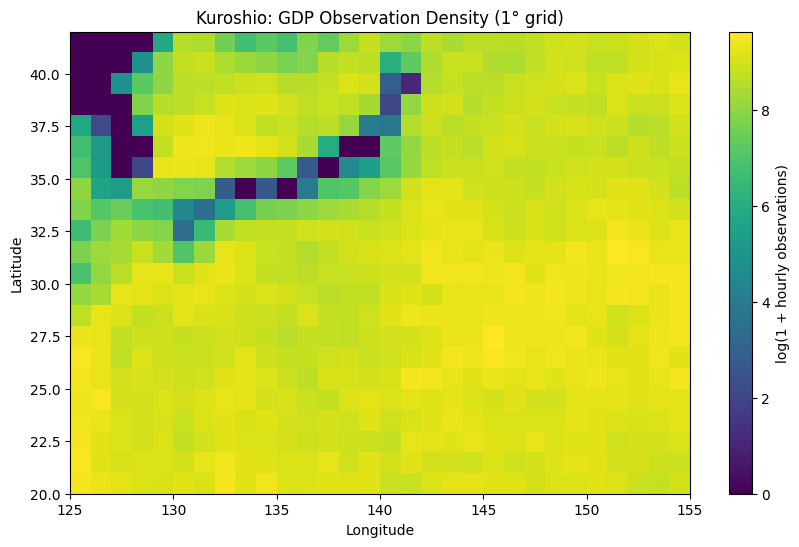

In [4]:
for name, d in density.items():

    plt.figure(figsize=(10, 6))

    # log1p 防止少数超高密度格子把其他区域全部压暗
    plt.imshow(
        np.log1p(d["grid"]),
        origin="lower",
        extent=[
            d["lon_edges"][0],
            d["lon_edges"][-1],
            d["lat_edges"][0],
            d["lat_edges"][-1]
        ],
        aspect="auto"
    )

    plt.colorbar(label="log(1 + hourly observations)")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.title(f"{name}: GDP Observation Density (1° grid)")

    plt.show()

In [5]:
import numpy as np
import pandas as pd

# ============================================================
# GLOBAL GDP SCREENING
# 10° x 10° boxes
# Metrics:
#   1. Total hourly observations
#   2. Distinct drifters
# ============================================================

GRID_SIZE = 10
CHUNK_SIZE = 1_000_000

# Global grid edges
lon_edges = np.arange(-180, 180 + GRID_SIZE, GRID_SIZE)
lat_edges = np.arange(-90, 90 + GRID_SIZE, GRID_SIZE)

n_lon = len(lon_edges) - 1
n_lat = len(lat_edges) - 1
n_boxes = n_lon * n_lat

print(f"Grid: {n_lon} longitude bins × {n_lat} latitude bins")
print(f"Total boxes: {n_boxes}")

# ------------------------------------------------------------
# 1. Prepare observation counts
# ------------------------------------------------------------

obs_counts = np.zeros(n_boxes, dtype=np.int64)

# For distinct drifters:
# store pairs of (grid_box, trajectory_index)
# There are only 19,396 trajectories, so this remains manageable.
box_drifter_pairs = set()

# rowsize describes the contiguous ragged trajectory structure
rowsize = ds["rowsize"].values
boundaries = np.cumsum(rowsize)

n_obs = ds.sizes["obs"]

# ------------------------------------------------------------
# 2. Scan the real GDP hourly dataset in chunks
# ------------------------------------------------------------

for start in range(0, n_obs, CHUNK_SIZE):

    end = min(start + CHUNK_SIZE, n_obs)

    # Load only one chunk into RAM
    lon = ds["lon"].isel(obs=slice(start, end)).values
    lat = ds["lat"].isel(obs=slice(start, end)).values

    # Remove invalid coordinates
    valid = (
        np.isfinite(lon) &
        np.isfinite(lat) &
        (lon >= -180) & (lon <= 180) &
        (lat >= -90) & (lat <= 90)
    )

    lon_valid = lon[valid]
    lat_valid = lat[valid]

    # Convert longitude/latitude to grid indices
    lon_idx = np.floor((lon_valid + 180) / GRID_SIZE).astype(int)
    lat_idx = np.floor((lat_valid + 90) / GRID_SIZE).astype(int)

    # Handle exact boundary values such as lon = 180
    lon_idx = np.clip(lon_idx, 0, n_lon - 1)
    lat_idx = np.clip(lat_idx, 0, n_lat - 1)

    # Unique integer ID for every 10° × 10° box
    box_id = lat_idx * n_lon + lon_idx

    # --------------------------------------------------------
    # Count observations
    # --------------------------------------------------------

    counts = np.bincount(box_id, minlength=n_boxes)
    obs_counts += counts

    # --------------------------------------------------------
    # Identify which drifter each valid observation belongs to
    # --------------------------------------------------------

    local_positions = np.nonzero(valid)[0]
    global_positions = local_positions + start

    traj_idx = np.searchsorted(
        boundaries,
        global_positions,
        side="right"
    )

    # We only need unique (box, drifter) pairs within this chunk
    pairs = np.unique(
        np.column_stack((box_id, traj_idx)),
        axis=0
    )

    box_drifter_pairs.update(
        map(tuple, pairs)
    )

    # Progress
    if start % 10_000_000 == 0:
        print(
            f"Processed {start:,} / {n_obs:,} "
            f"({100 * start / n_obs:.1f}%)"
        )

print("Global scan finished.")

# ------------------------------------------------------------
# 3. Count distinct drifters per box
# ------------------------------------------------------------

drifter_counts = np.zeros(n_boxes, dtype=np.int64)

for box, traj in box_drifter_pairs:
    drifter_counts[box] += 1

# ------------------------------------------------------------
# 4. Build results table
# ------------------------------------------------------------

records = []

for lat_i in range(n_lat):
    for lon_i in range(n_lon):

        box = lat_i * n_lon + lon_i

        west = lon_edges[lon_i]
        east = lon_edges[lon_i + 1]
        south = lat_edges[lat_i]
        north = lat_edges[lat_i + 1]

        records.append({
            "Box_ID": box,
            "West": west,
            "East": east,
            "South": south,
            "North": north,
            "Observations": int(obs_counts[box]),
            "Distinct_drifters": int(drifter_counts[box])
        })

global_screen = pd.DataFrame(records)

# Remove boxes with zero observations
global_screen = global_screen[
    global_screen["Observations"] > 0
].copy()

# ------------------------------------------------------------
# 5. Rank
# ------------------------------------------------------------

global_screen = global_screen.sort_values(
    ["Distinct_drifters", "Observations"],
    ascending=False
).reset_index(drop=True)

global_screen["Rank_by_drifters"] = (
    global_screen["Distinct_drifters"]
    .rank(method="min", ascending=False)
    .astype(int)
)

global_screen["Rank_by_observations"] = (
    global_screen["Observations"]
    .rank(method="min", ascending=False)
    .astype(int)
)

print("\n=== TOP 30 GLOBAL 10° × 10° BOXES ===")

print(
    global_screen[
        [
            "West", "East",
            "South", "North",
            "Observations",
            "Distinct_drifters",
            "Rank_by_drifters",
            "Rank_by_observations"
        ]
    ]
    .head(30)
    .to_string(index=False)
)

Grid: 36 longitude bins × 18 latitude bins
Total boxes: 648
Processed 0 / 197,214,787 (0.0%)
Processed 10,000,000 / 197,214,787 (5.1%)
Processed 20,000,000 / 197,214,787 (10.1%)
Processed 30,000,000 / 197,214,787 (15.2%)
Processed 40,000,000 / 197,214,787 (20.3%)
Processed 50,000,000 / 197,214,787 (25.4%)
Processed 60,000,000 / 197,214,787 (30.4%)
Processed 70,000,000 / 197,214,787 (35.5%)
Processed 80,000,000 / 197,214,787 (40.6%)
Processed 90,000,000 / 197,214,787 (45.6%)
Processed 100,000,000 / 197,214,787 (50.7%)
Processed 110,000,000 / 197,214,787 (55.8%)
Processed 120,000,000 / 197,214,787 (60.8%)
Processed 130,000,000 / 197,214,787 (65.9%)
Processed 140,000,000 / 197,214,787 (71.0%)
Processed 150,000,000 / 197,214,787 (76.1%)
Processed 160,000,000 / 197,214,787 (81.1%)
Processed 170,000,000 / 197,214,787 (86.2%)
Processed 180,000,000 / 197,214,787 (91.3%)
Processed 190,000,000 / 197,214,787 (96.3%)
Global scan finished.

=== TOP 30 GLOBAL 10° × 10° BOXES ===
 West  East  South  

In [6]:
# Add a simple trajectory-richness screening metric
global_screen["Obs_per_drifter"] = (
    global_screen["Observations"] /
    global_screen["Distinct_drifters"]
)

# Require a reasonable number of distinct drifters first
screened = global_screen[
    global_screen["Distinct_drifters"] >= 300
].copy()

# Show boxes that are strong on BOTH observations and drifter count
screened["Combined_rank"] = (
    screened["Rank_by_drifters"] +
    screened["Rank_by_observations"]
)

screened = screened.sort_values(
    "Combined_rank"
)

print("=== BOXES STRONG ON BOTH METRICS ===")

print(
    screened[
        [
            "West", "East",
            "South", "North",
            "Observations",
            "Distinct_drifters",
            "Obs_per_drifter",
            "Rank_by_drifters",
            "Rank_by_observations",
            "Combined_rank"
        ]
    ]
    .head(30)
    .to_string(index=False)
)

=== BOXES STRONG ON BOTH METRICS ===
 West  East  South  North  Observations  Distinct_drifters  Obs_per_drifter  Rank_by_drifters  Rank_by_observations  Combined_rank
  -60   -50     30     40       1831330                823      2225.188335                 5                     5             10
  -70   -60     30     40       1639025                814      2013.544226                 7                     8             15
  -50   -40     40     50       1199723                829      1447.193004                 4                    16             20
  -50   -40     30     40       1852011                723      2561.564315                16                     4             20
  -40   -30     40     50       1148541                734      1564.769755                13                    21             34
  -50   -40     20     30       2057073                599      3434.178631                34                     1             35
  -40   -30     20     30       1782097       

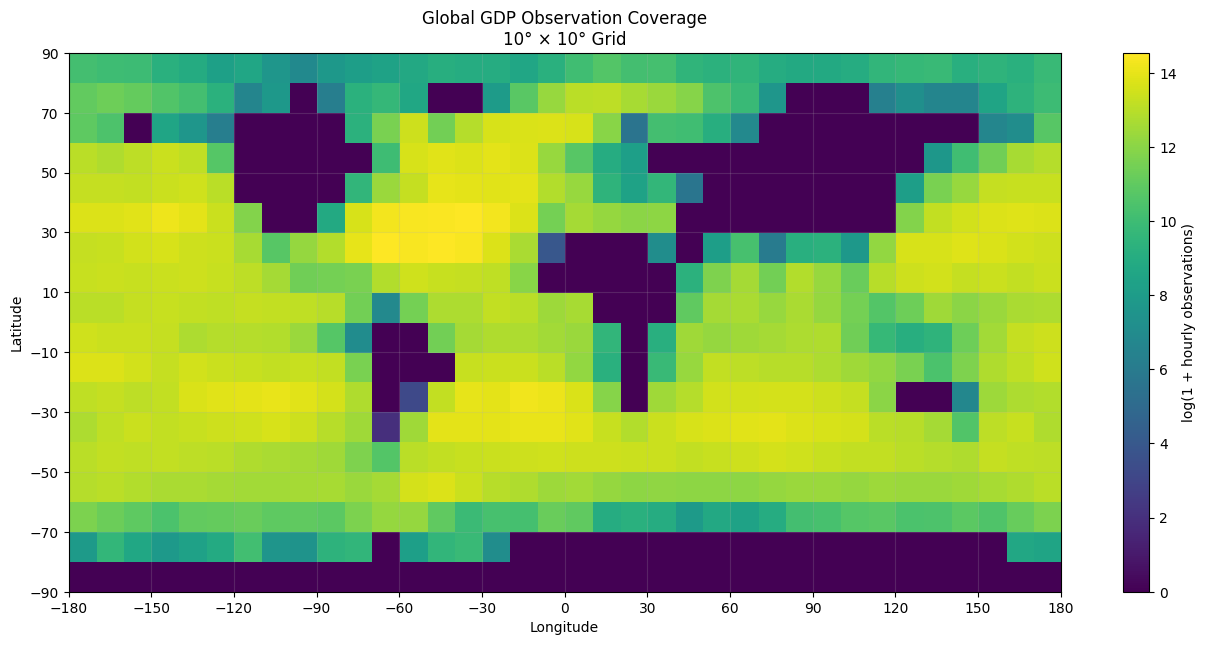

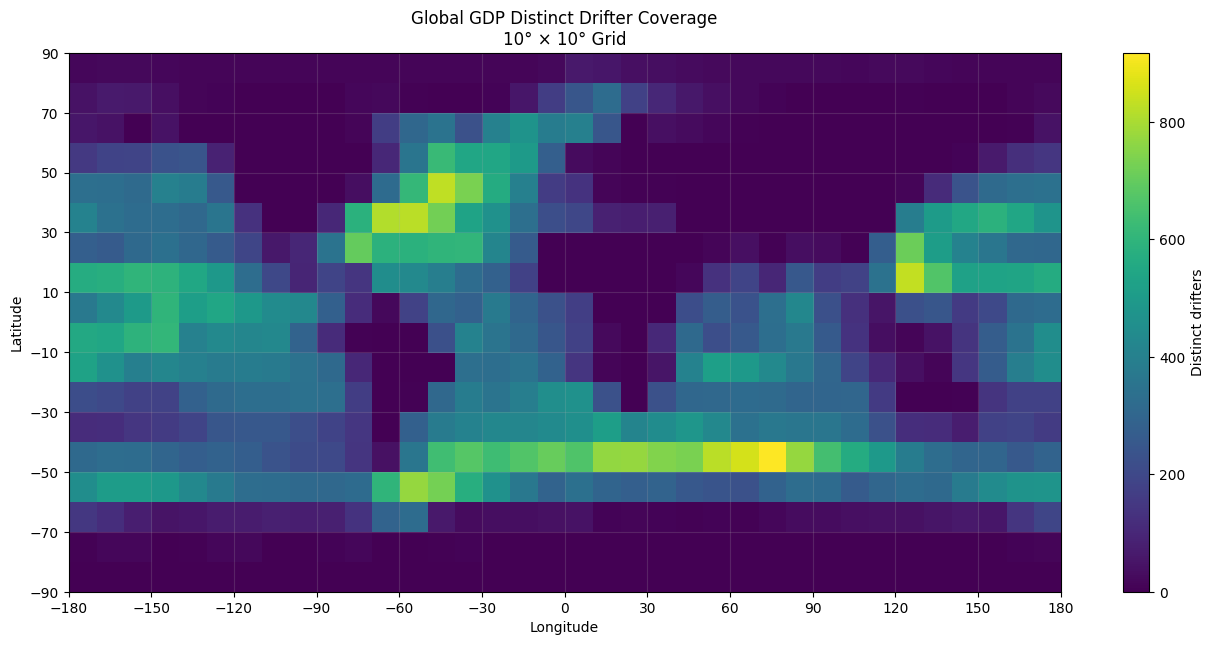

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Reconstruct global 10° × 10° grids from global_screen
# ============================================================

GRID_SIZE = 10

lon_edges = np.arange(-180, 181, GRID_SIZE)
lat_edges = np.arange(-90, 91, GRID_SIZE)

n_lon = len(lon_edges) - 1
n_lat = len(lat_edges) - 1

obs_grid = np.zeros((n_lat, n_lon))
drifter_grid = np.zeros((n_lat, n_lon))

for _, row in global_screen.iterrows():

    lon_i = int((row["West"] + 180) / GRID_SIZE)
    lat_i = int((row["South"] + 90) / GRID_SIZE)

    obs_grid[lat_i, lon_i] = row["Observations"]
    drifter_grid[lat_i, lon_i] = row["Distinct_drifters"]


# ============================================================
# MAP 1: Global observation heatmap
# ============================================================

plt.figure(figsize=(16, 7))

plt.imshow(
    np.log1p(obs_grid),
    origin="lower",
    extent=[-180, 180, -90, 90],
    aspect="auto"
)

plt.colorbar(label="log(1 + hourly observations)")

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title(
    "Global GDP Observation Coverage\n"
    "10° × 10° Grid"
)

plt.xticks(np.arange(-180, 181, 30))
plt.yticks(np.arange(-90, 91, 20))

plt.grid(alpha=0.2)

plt.show()


# ============================================================
# MAP 2: Global distinct-drifter heatmap
# ============================================================

plt.figure(figsize=(16, 7))

plt.imshow(
    drifter_grid,
    origin="lower",
    extent=[-180, 180, -90, 90],
    aspect="auto"
)

plt.colorbar(label="Distinct drifters")

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title(
    "Global GDP Distinct Drifter Coverage\n"
    "10° × 10° Grid"
)

plt.xticks(np.arange(-180, 181, 30))
plt.yticks(np.arange(-90, 91, 20))

plt.grid(alpha=0.2)

plt.show()

In [8]:
try:
    import cartopy
    print("Cartopy is installed.")
except ImportError:
    print("Cartopy is NOT installed.")

Cartopy is NOT installed.


In [9]:
!pip -q install cartopy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 58.0 MB/s eta 0:00:00


In [10]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

print("Cartopy ready!")

Cartopy ready!


/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


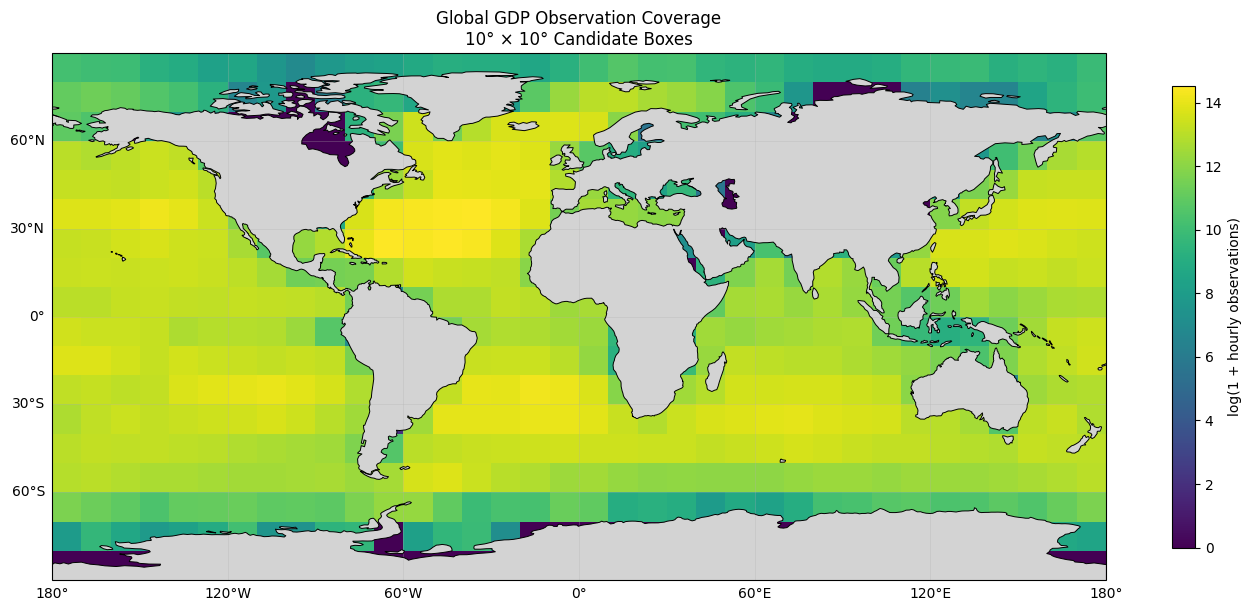

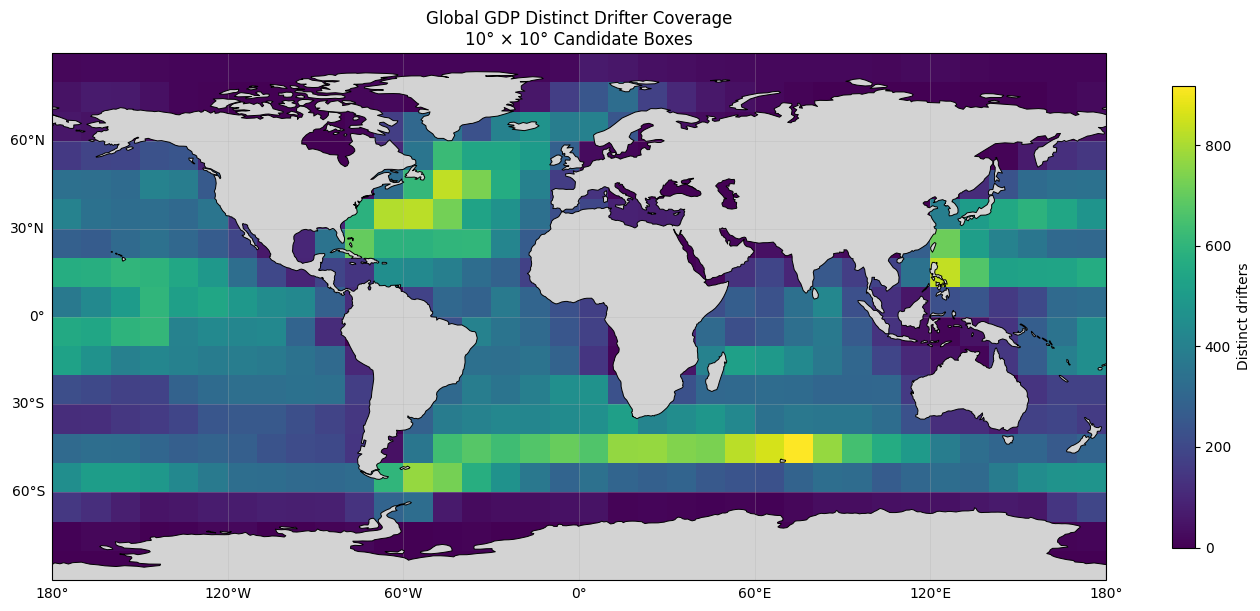

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ============================================================
# MAP 1 — Global observation coverage
# ============================================================

fig = plt.figure(figsize=(17, 8))

ax = plt.axes(
    projection=ccrs.PlateCarree()
)

mesh = ax.pcolormesh(
    lon_edges,
    lat_edges,
    np.log1p(obs_grid),
    transform=ccrs.PlateCarree()
)

# Add geographic context
ax.add_feature(
    cfeature.LAND,
    facecolor="lightgray",
    zorder=2
)

ax.coastlines(
    linewidth=0.7,
    zorder=3
)

ax.set_global()

gl = ax.gridlines(
    draw_labels=True,
    linewidth=0.4,
    alpha=0.5
)

gl.top_labels = False
gl.right_labels = False

plt.colorbar(
    mesh,
    ax=ax,
    orientation="vertical",
    shrink=0.75,
    label="log(1 + hourly observations)"
)

plt.title(
    "Global GDP Observation Coverage\n"
    "10° × 10° Candidate Boxes"
)

plt.show()


# ============================================================
# MAP 2 — Global distinct drifter coverage
# ============================================================

fig = plt.figure(figsize=(17, 8))

ax = plt.axes(
    projection=ccrs.PlateCarree()
)

mesh = ax.pcolormesh(
    lon_edges,
    lat_edges,
    drifter_grid,
    transform=ccrs.PlateCarree()
)

ax.add_feature(
    cfeature.LAND,
    facecolor="lightgray",
    zorder=2
)

ax.coastlines(
    linewidth=0.7,
    zorder=3
)

ax.set_global()

gl = ax.gridlines(
    draw_labels=True,
    linewidth=0.4,
    alpha=0.5
)

gl.top_labels = False
gl.right_labels = False

plt.colorbar(
    mesh,
    ax=ax,
    orientation="vertical",
    shrink=0.75,
    label="Distinct drifters"
)

plt.title(
    "Global GDP Distinct Drifter Coverage\n"
    "10° × 10° Candidate Boxes"
)

plt.show()

In [12]:
# ============================================================
# STAGE 2A — Candidate boxes strong on BOTH metrics
# ============================================================

candidates = global_screen.copy()

# Percentile rank: 0–100, higher = stronger
candidates["Obs_percentile"] = (
    candidates["Observations"].rank(pct=True) * 100
)

candidates["Drifter_percentile"] = (
    candidates["Distinct_drifters"].rank(pct=True) * 100
)

# First screening:
# Require BOTH metrics to be in the top 20% of non-empty boxes
shortlist = candidates[
    (candidates["Obs_percentile"] >= 80) &
    (candidates["Drifter_percentile"] >= 80)
].copy()

# For DISPLAY ONLY:
# average percentile helps order the shortlist
shortlist["Screening_index"] = (
    shortlist["Obs_percentile"] +
    shortlist["Drifter_percentile"]
) / 2

shortlist = shortlist.sort_values(
    "Screening_index",
    ascending=False
).reset_index(drop=True)

print("Number of candidate boxes:", len(shortlist))

print("\n=== GLOBAL SHORTLIST ===")

print(
    shortlist[
        [
            "West", "East",
            "South", "North",
            "Observations",
            "Distinct_drifters",
            "Obs_percentile",
            "Drifter_percentile",
            "Screening_index"
        ]
    ]
    .head(30)
    .round(1)
    .to_string(index=False)
)

Number of candidate boxes: 51

=== GLOBAL SHORTLIST ===
 West  East  South  North  Observations  Distinct_drifters  Obs_percentile  Drifter_percentile  Screening_index
  -60   -50     30     40       1831330                823            99.2                99.1             99.2
  -70   -60     30     40       1639025                814            98.6                98.8             98.7
  -50   -40     40     50       1199723                829            97.1                99.4             98.3
  -50   -40     30     40       1852011                723            99.4                97.1             98.3
  -40   -30     40     50       1148541                734            96.1                97.6             96.8
  -50   -40     20     30       2057073                599           100.0                93.6             96.8
  -40   -30     20     30       1782097                604            98.8                94.4             96.6
  -80   -70     20     30       1178645         

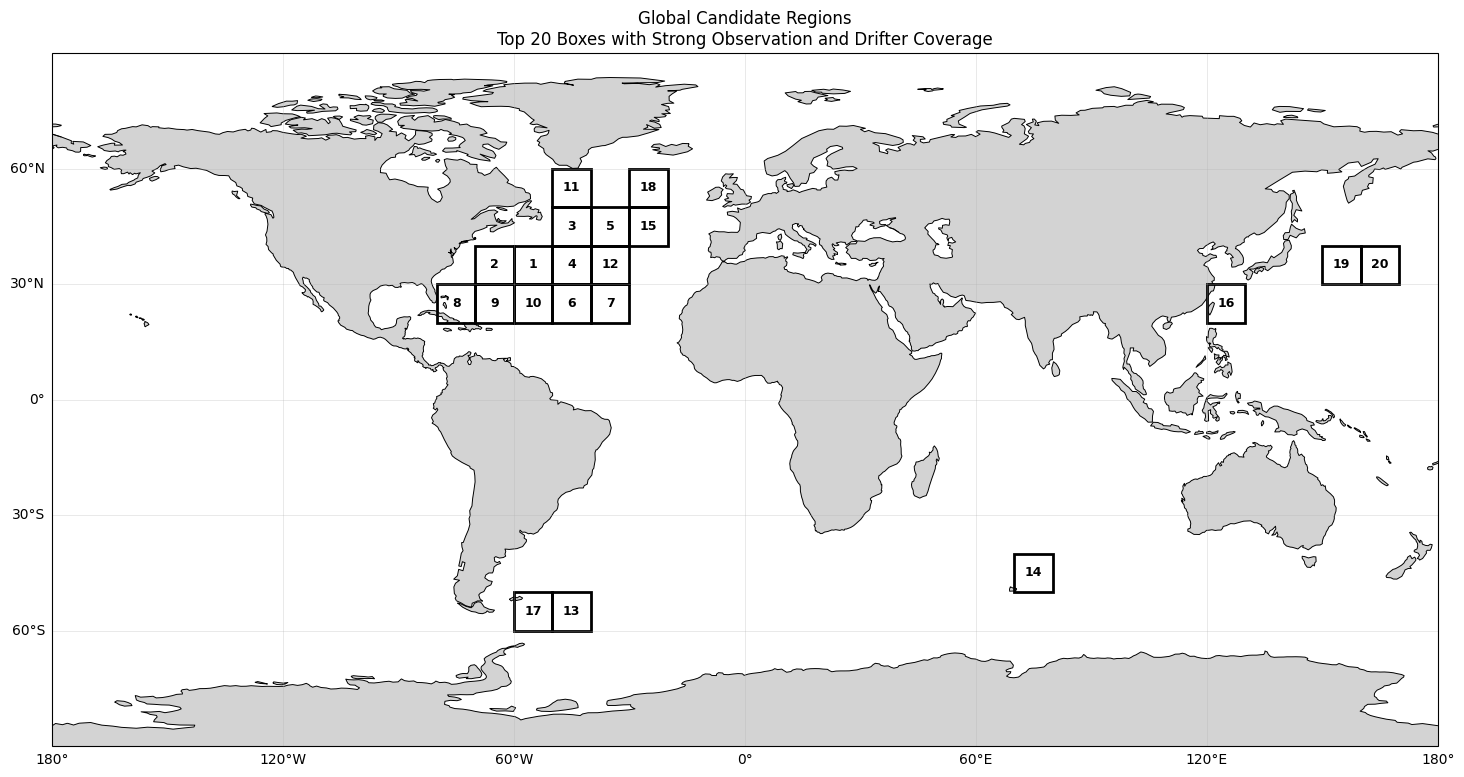

In [13]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Show first 20 strongest candidate boxes
top_candidates = shortlist.head(20).copy()

fig = plt.figure(figsize=(18, 9))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_global()

ax.add_feature(
    cfeature.LAND,
    facecolor="lightgray"
)

ax.coastlines(linewidth=0.7)

# Draw candidate boxes
for i, row in top_candidates.iterrows():

    west = row["West"]
    east = row["East"]
    south = row["South"]
    north = row["North"]

    rect = patches.Rectangle(
        (west, south),
        east - west,
        north - south,
        fill=False,
        linewidth=2,
        transform=ccrs.PlateCarree()
    )

    ax.add_patch(rect)

    # Number the box
    ax.text(
        (west + east) / 2,
        (south + north) / 2,
        str(i + 1),
        horizontalalignment="center",
        verticalalignment="center",
        fontsize=9,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )

gl = ax.gridlines(
    draw_labels=True,
    linewidth=0.4,
    alpha=0.5
)

gl.top_labels = False
gl.right_labels = False

plt.title(
    "Global Candidate Regions\n"
    "Top 20 Boxes with Strong Observation and Drifter Coverage"
)

plt.show()

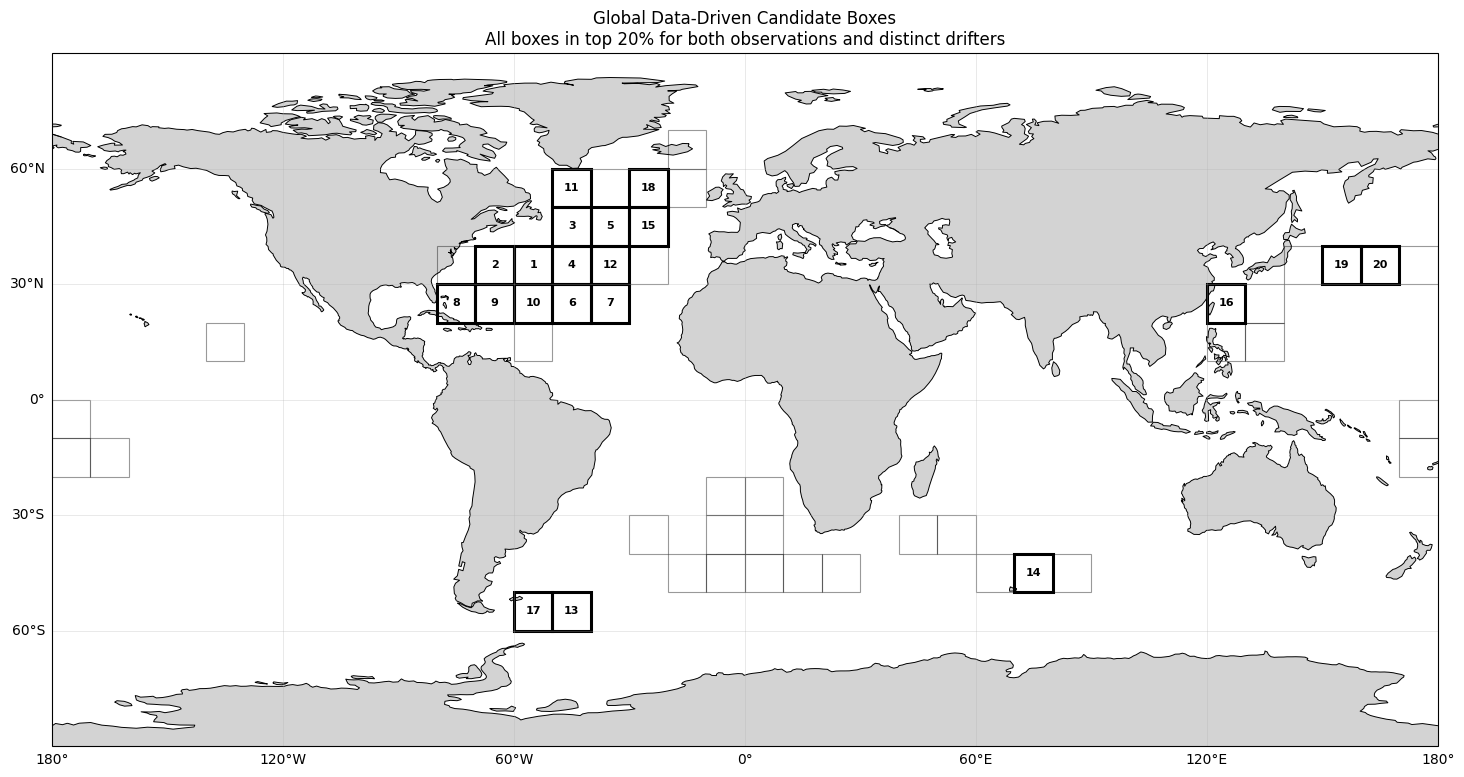

In [14]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cartopy.crs as ccrs
import cartopy.feature as cfeature

fig = plt.figure(figsize=(18, 9))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_global()
ax.add_feature(cfeature.LAND, facecolor="lightgray")
ax.coastlines(linewidth=0.7)

# ------------------------------------------------------------
# Draw ALL 51 candidate boxes
# ------------------------------------------------------------

for _, row in shortlist.iterrows():

    rect = patches.Rectangle(
        (row["West"], row["South"]),
        row["East"] - row["West"],
        row["North"] - row["South"],
        fill=False,
        linewidth=0.8,
        alpha=0.4,
        transform=ccrs.PlateCarree()
    )

    ax.add_patch(rect)


# ------------------------------------------------------------
# Highlight Top 20
# ------------------------------------------------------------

for i, row in shortlist.head(20).iterrows():

    rect = patches.Rectangle(
        (row["West"], row["South"]),
        row["East"] - row["West"],
        row["North"] - row["South"],
        fill=False,
        linewidth=2.2,
        transform=ccrs.PlateCarree()
    )

    ax.add_patch(rect)

    ax.text(
        (row["West"] + row["East"]) / 2,
        (row["South"] + row["North"]) / 2,
        str(i + 1),
        ha="center",
        va="center",
        fontsize=8,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )


gl = ax.gridlines(
    draw_labels=True,
    linewidth=0.4,
    alpha=0.5
)

gl.top_labels = False
gl.right_labels = False

plt.title(
    "Global Data-Driven Candidate Boxes\n"
    "All boxes in top 20% for both observations and distinct drifters"
)

plt.show()

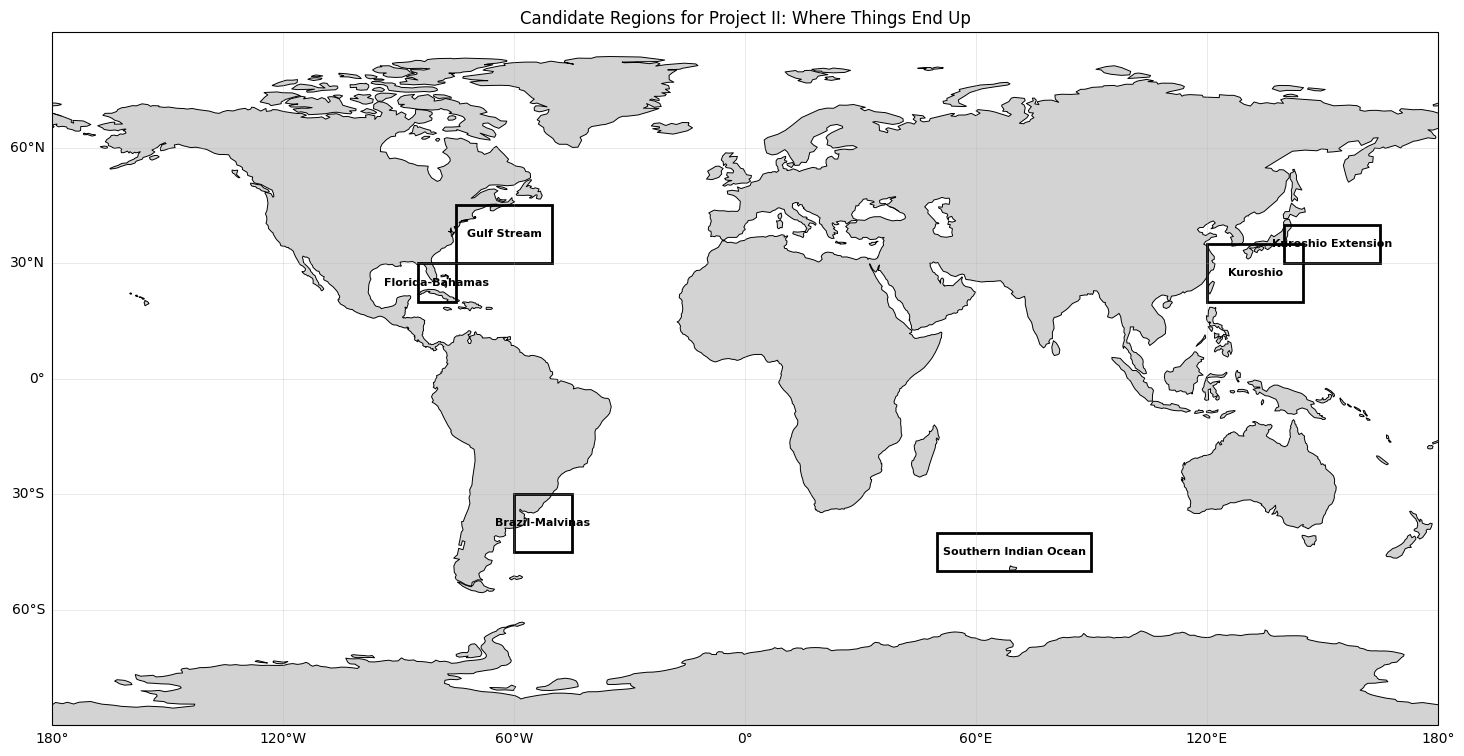

In [15]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cartopy.crs as ccrs
import cartopy.feature as cfeature

candidate_regions = {
    "Florida-Bahamas": (-85, -75, 20, 30),
    "Gulf Stream": (-75, -50, 30, 45),
    "Kuroshio": (120, 145, 20, 35),
    "Kuroshio Extension": (140, 165, 30, 40),
    "Brazil-Malvinas": (-60, -45, -45, -30),
    "Southern Indian Ocean": (50, 90, -50, -40)
}

fig = plt.figure(figsize=(18, 9))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_global()
ax.add_feature(cfeature.LAND, facecolor="lightgray")
ax.coastlines(linewidth=0.7)

for name, (west, east, south, north) in candidate_regions.items():

    rect = patches.Rectangle(
        (west, south),
        east - west,
        north - south,
        fill=False,
        linewidth=2,
        transform=ccrs.PlateCarree()
    )

    ax.add_patch(rect)

    ax.text(
        (west + east) / 2,
        (south + north) / 2,
        name,
        ha="center",
        va="center",
        fontsize=8,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )

gl = ax.gridlines(draw_labels=True, linewidth=0.4, alpha=0.5)
gl.top_labels = False
gl.right_labels = False

plt.title("Candidate Regions for Project II: Where Things End Up")
plt.show()

In [20]:
import numpy as np
import pandas as pd
import time

# ============================================================
# FAST TWO-STAGE TRAJECTORY SCREEN
# Stage A: chunk scan to identify relevant trajectories
# Stage B: only read trajectories that entered >=1 region
# ============================================================

candidate_regions = {
    "Florida-Bahamas": (-85, -75, 20, 30),
    "Gulf Stream": (-75, -50, 30, 45),
    "Kuroshio": (120, 145, 20, 35),
    "Kuroshio Extension": (140, 165, 30, 40),
    "Brazil-Malvinas": (-60, -45, -45, -30),
    "Southern Indian Ocean": (50, 90, -50, -40)
}

rowsize = ds["rowsize"].values.astype(np.int64)

traj_starts = np.concatenate(([0], np.cumsum(rowsize)[:-1]))
traj_ends = np.cumsum(rowsize)

n_obs = int(traj_ends[-1])
n_traj = len(rowsize)

# Which trajectory owns each observation?
# We will determine this from cumulative trajectory ends.
traj_ends_search = traj_ends

# Store candidate trajectory indices for each region
region_trajs = {
    name: set()
    for name in candidate_regions
}

# ------------------------------------------------------------
# STAGE A
# Scan lat/lon in large chunks
# ------------------------------------------------------------

CHUNK = 2_000_000

print("STAGE A: Finding trajectories that enter each region...")
print(f"Total observations: {n_obs:,}")

t_start = time.time()

for start in range(0, n_obs, CHUNK):

    end = min(start + CHUNK, n_obs)

    lat = ds["lat"].isel(obs=slice(start, end)).values
    lon = ds["lon"].isel(obs=slice(start, end)).values

    valid = np.isfinite(lat) & np.isfinite(lon)

    if np.any(valid):

        # Global observation indices in this chunk
        obs_idx = np.arange(start, end, dtype=np.int64)

        # Convert observation index -> trajectory index
        traj_idx = np.searchsorted(
            traj_ends_search,
            obs_idx,
            side="right"
        )

        for name, (west, east, south, north) in candidate_regions.items():

            inside = (
                valid &
                (lon >= west) &
                (lon < east) &
                (lat >= south) &
                (lat < north)
            )

            if np.any(inside):
                region_trajs[name].update(
                    np.unique(traj_idx[inside]).tolist()
                )

    done = end / n_obs * 100

    print(
        f"{end:,} / {n_obs:,} observations "
        f"({done:.1f}%)"
    )

print(
    f"\nStage A finished in "
    f"{(time.time()-t_start)/60:.1f} minutes."
)

print("\nCandidate trajectories:")
for name in candidate_regions:
    print(
        f"{name:25s}: "
        f"{len(region_trajs[name]):,}"
    )

STAGE A: Finding trajectories that enter each region...
Total observations: 197,214,787
2,000,000 / 197,214,787 observations (1.0%)
4,000,000 / 197,214,787 observations (2.0%)
6,000,000 / 197,214,787 observations (3.0%)
8,000,000 / 197,214,787 observations (4.1%)
10,000,000 / 197,214,787 observations (5.1%)
12,000,000 / 197,214,787 observations (6.1%)
14,000,000 / 197,214,787 observations (7.1%)
16,000,000 / 197,214,787 observations (8.1%)
18,000,000 / 197,214,787 observations (9.1%)
20,000,000 / 197,214,787 observations (10.1%)
22,000,000 / 197,214,787 observations (11.2%)
24,000,000 / 197,214,787 observations (12.2%)
26,000,000 / 197,214,787 observations (13.2%)
28,000,000 / 197,214,787 observations (14.2%)
30,000,000 / 197,214,787 observations (15.2%)
32,000,000 / 197,214,787 observations (16.2%)
34,000,000 / 197,214,787 observations (17.2%)
36,000,000 / 197,214,787 observations (18.3%)
38,000,000 / 197,214,787 observations (19.3%)
40,000,000 / 197,214,787 observations (20.3%)
42,00

Florida–Bahamas observations: 522,641
Florida–Bahamas distinct drifters: 608


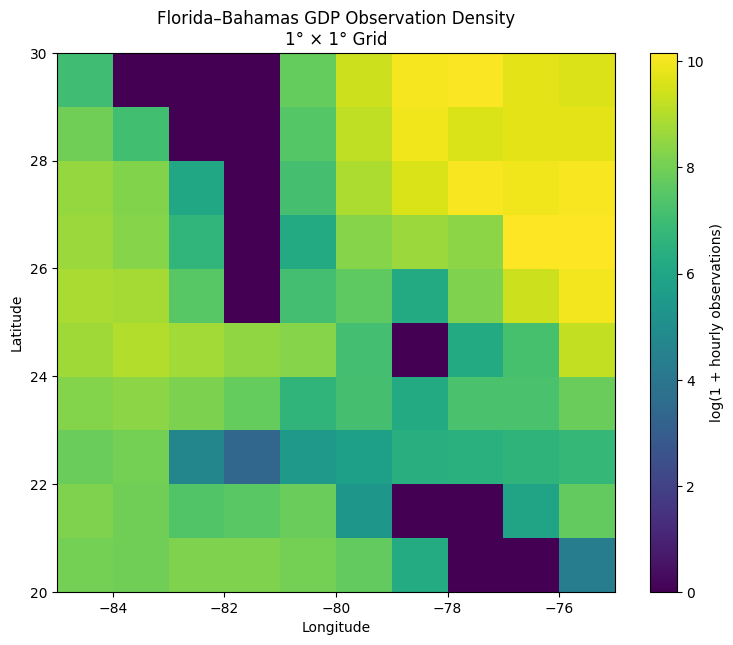

In [21]:
# ============================================================
# Florida–Bahamas: observations + 1° density map
# Region: 85–75°W, 20–30°N
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

west, east = -85, -75
south, north = 20, 30

CHUNK = 2_000_000
n_obs = ds.sizes["obs"]

total_obs = 0

# 1° × 1° density grid
lon_edges_fb = np.arange(west, east + 1, 1)
lat_edges_fb = np.arange(south, north + 1, 1)

density_fb = np.zeros(
    (len(lat_edges_fb) - 1, len(lon_edges_fb) - 1),
    dtype=np.int64
)

for start in range(0, n_obs, CHUNK):

    end = min(start + CHUNK, n_obs)

    lat = ds["lat"].isel(obs=slice(start, end)).values
    lon = ds["lon"].isel(obs=slice(start, end)).values

    valid = np.isfinite(lat) & np.isfinite(lon)

    inside = (
        valid &
        (lon >= west) &
        (lon < east) &
        (lat >= south) &
        (lat < north)
    )

    total_obs += inside.sum()

    if np.any(inside):

        hist, _, _ = np.histogram2d(
            lat[inside],
            lon[inside],
            bins=[lat_edges_fb, lon_edges_fb]
        )

        density_fb += hist.astype(np.int64)


print(f"Florida–Bahamas observations: {total_obs:,}")
print("Florida–Bahamas distinct drifters: 608")


# ============================================================
# Density map
# ============================================================

plt.figure(figsize=(9, 7))

plt.imshow(
    np.log1p(density_fb),
    origin="lower",
    extent=[west, east, south, north],
    aspect="auto"
)

plt.colorbar(label="log(1 + hourly observations)")

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.title(
    "Florida–Bahamas GDP Observation Density\n"
    "1° × 1° Grid"
)

plt.show()

In [1]:
# ============================================================
# STAGE B
# Check 7-day, 30-day and 1-year destination availability
# FINAL REGION: Florida-Bahamas
# ============================================================

import numpy as np
import pandas as pd
import time

regions_to_test = {
    "Florida-Bahamas": candidate_regions["Florida-Bahamas"]
}

TOLERANCE_HOURS = 3
tolerance = np.timedelta64(TOLERANCE_HOURS, "h")

results = []

print("STAGE B: Checking 7-day, 30-day and 1-year trajectory continuity...")
print(f"Tolerance: ±{TOLERANCE_HOURS} hours\n")

t_start = time.time()

for region_name, (west, east, south, north) in regions_to_test.items():

    candidate_ids = sorted(region_trajs[region_name])

    valid_7d = 0
    valid_30d = 0
    valid_365d = 0
    valid_all = 0
    actual_entries = 0

    print(
        f"Processing {region_name}: "
        f"{len(candidate_ids):,} candidate trajectories"
    )

    for j, traj_idx in enumerate(candidate_ids):

        start = traj_starts[traj_idx]
        end = traj_ends[traj_idx]

        # Read this trajectory only once
        lat = ds["lat"].isel(obs=slice(start, end)).values
        lon = ds["lon"].isel(obs=slice(start, end)).values
        time_arr = ds["time"].isel(obs=slice(start, end)).values

        # Valid observations
        valid = (
            np.isfinite(lat) &
            np.isfinite(lon) &
            ~np.isnat(time_arr)
        )

        # Observations inside Region R
        inside = (
            valid &
            (lon >= west) &
            (lon < east) &
            (lat >= south) &
            (lat < north)
        )

        if not np.any(inside):
            continue

        actual_entries += 1

        # ----------------------------------------------------
        # t0 = first valid observation inside Region R
        # ----------------------------------------------------
        first_inside_idx = np.flatnonzero(inside)[0]
        t0 = time_arr[first_inside_idx]

        target_7d = t0 + np.timedelta64(7, "D")
        target_30d = t0 + np.timedelta64(30, "D")
        target_365d = t0 + np.timedelta64(365, "D")

        # Only valid observations at or after t0
        later_times = time_arr[valid & (time_arr >= t0)]

        # ----------------------------------------------------
        # Is there an observation within ±3h of each target?
        # ----------------------------------------------------
        has_7d = np.any(
            np.abs(later_times - target_7d) <= tolerance
        )

        has_30d = np.any(
            np.abs(later_times - target_30d) <= tolerance
        )

        has_365d = np.any(
            np.abs(later_times - target_365d) <= tolerance
        )

        valid_7d += int(has_7d)
        valid_30d += int(has_30d)
        valid_365d += int(has_365d)

        valid_all += int(
            has_7d and has_30d and has_365d
        )

        if (j + 1) % 100 == 0:
            print(
                f"  {j+1:,} / {len(candidate_ids):,}"
            )

    results.append({
        "Region": region_name,
        "Entering_trajectories": actual_entries,

        "Valid_7d": valid_7d,
        "Valid_7d_pct": (
            100 * valid_7d / actual_entries
            if actual_entries else np.nan
        ),

        "Valid_30d": valid_30d,
        "Valid_30d_pct": (
            100 * valid_30d / actual_entries
            if actual_entries else np.nan
        ),

        "Valid_365d": valid_365d,
        "Valid_365d_pct": (
            100 * valid_365d / actual_entries
            if actual_entries else np.nan
        ),

        "Valid_all": valid_all,
        "Valid_all_pct": (
            100 * valid_all / actual_entries
            if actual_entries else np.nan
        )
    })

    print(
        f"Finished {region_name}: "
        f"7d={valid_7d:,}, "
        f"30d={valid_30d:,}, "
        f"365d={valid_365d:,}\n"
    )


# ============================================================
# RESULTS
# ============================================================

continuity_results = pd.DataFrame(results)

print("=" * 85)
print("TRAJECTORY CONTINUITY RESULTS")
print("=" * 85)

display(
    continuity_results.style.format({
        "Valid_7d_pct": "{:.1f}%",
        "Valid_30d_pct": "{:.1f}%",
        "Valid_365d_pct": "{:.1f}%",
        "Valid_all_pct": "{:.1f}%"
    })
)

print(
    f"\nStage B finished in "
    f"{(time.time()-t_start)/60:.1f} minutes."
)

NameError: name 'candidate_regions' is not defined

In [9]:
import numpy as np
import pandas as pd
import time
import clouddrift as cd

ds = cd.datasets.gdp1h()

print(ds)

AttributeError: module 'numpy._core._multiarray_umath' has no attribute '_blas_supports_fpe'